# Alerta Respiratoria Gran Concepción

**Estructura**

- **Parte A, el código:** configuración y funciones (lectura de datos, panel semanal, modelo, colas, gráficos y descargas). Lo único que deberían editar es la celda de **configuración**.
- **Parte B, el análisis:** el flujo paso a paso, con explicación y resultados en cada sección.

**Cómo usarlo**

1. El notebook vive en `notebooks/` del repositorio SART y lee los datos de la raíz: `../datos/crudos` y `../datos/procesados` (reales, fuera de git) o `../datos/prueba/` (sintéticos). Los gráficos quedan en `notebooks/resultados/` (o `resultados_prueba/`), fuera de git.
2. Instalen las librerías (celda siguiente).
3. En la configuración del análisis (inicio de la Parte B), elijan `PRUEBA = True` (datos sintéticos) o `PRUEBA = False` con `DESCARGAR = True` (datos reales).
4. *Kernel → Restart & Run All*.

> Si cambian una función, cambien también el `.py` correspondiente del proyecto (o al revés), para que no queden dos versiones distintas del código.


In [3]:
# Instalar las librerías (solo la primera vez)
# %pip install pandas pyarrow numpy statsmodels matplotlib epiweeks requests openpyxl

In [4]:
import datetime as dt
import math
import re
import sys
import unicodedata
from dataclasses import dataclass
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import statsmodels.formula.api as smf
from epiweeks import Week
from IPython.display import Image, Markdown, display

# Parte A: el código

## A1. Configuración
Rutas, fuentes, comunas, estaciones y todos los supuestos. Lo marcado `# REVISAR` es tarea del equipo: códigos de las estaciones de SINCA, estación asignada a cada comuna, norma de MP2,5 y supuestos de dotación.

In [5]:
from dataclasses import dataclass
from pathlib import Path

CARPETA = Path.cwd()  # carpeta donde está este notebook (notebooks/ del repositorio)
RAIZ = CARPETA.parent  # raíz del repositorio SART: ahí está datos/

# ---------------------------------------------------------------------------
# Fuentes de datos (portal datos.gob.cl, Minsal / DEIS)
# ---------------------------------------------------------------------------
URL_SADU = (
    "https://datos.gob.cl/dataset/606ef5bb-11d1-475b-b69f-b980da5757f4/resource/"
    "ae6c9887-106d-4e98-8875-40bf2b836041/download/at_urg_respiratorio_semanal.parquet"
)
URL_SADU_DICCIONARIO = (
    "https://datos.gob.cl/dataset/606ef5bb-11d1-475b-b69f-b980da5757f4/resource/"
    "27fbe340-0e74-465f-b9f9-488c3bf6533c/download/"
    "diccionario-de-datos-urgenciasrespiratoriasporsemana.xlsx"
)
URL_ESTABLECIMIENTOS = (
    "https://datos.gob.cl/dataset/3bf4cf7c-f638-4735-9a01-f65faae4beca/resource/"
    "2c44d782-3365-44e3-aefb-2c8b8363a1bc/download/establecimientos_20260818.csv"
)
URL_ESTABLECIMIENTOS_DICCIONARIO = (
    "https://datos.gob.cl/dataset/3bf4cf7c-f638-4735-9a01-f65faae4beca/resource/"
    "7127fc99-b858-4e74-8971-51413e484fb1/download/diccionario-de-datos.pdf"
)

# ---------------------------------------------------------------------------
# Escenario: Concepción Metropolitano (10 comunas del plan de descontaminación)
# ---------------------------------------------------------------------------
COMUNAS = [
    "Concepción", "Talcahuano", "Hualpén", "San Pedro de la Paz", "Chiguayante",
    "Penco", "Tomé", "Coronel", "Lota", "Hualqui",
]

# Estaciones SINCA con MP2,5. "codigo" es el número que aparece en el enlace del
# gráfico de la ficha de la estación: macropath=./RVIII/<codigo>/Cal/PM25
# Solo se verificó el de Kingston College (827).  # REVISAR y completar
ESTACIONES = {
    "Kingston College": {"comuna": "Concepción", "ficha": 261, "codigo": "827"},
    "Punteras": {"comuna": "Chiguayante", "ficha": 235, "codigo": None},
    "Hualqui": {"comuna": "Hualqui", "ficha": 242, "codigo": None},
    "JUNJI": {"comuna": "Hualpén", "ficha": 43, "codigo": None},
    "Cerro Merquín": {"comuna": "Coronel", "ficha": 227, "codigo": None},
    "Coronel Norte": {"comuna": "Coronel", "ficha": 280, "codigo": None},
}

# Estación que representa la exposición de cada comuna.
# Comunas sin estación propia usan la más cercana.  # REVISAR
ESTACION_POR_COMUNA = {
    "Concepción": "Kingston College",
    "Chiguayante": "Punteras",
    "Hualqui": "Hualqui",
    "Hualpén": "JUNJI",
    "Talcahuano": "JUNJI",
    "Coronel": "Cerro Merquín",
    "Lota": "Cerro Merquín",
    "San Pedro de la Paz": "Kingston College",
    "Penco": "Kingston College",
    "Tomé": "Kingston College",
}
# Si una estación no tiene datos en alguna semana, se usa esta.
ESTACION_RESPALDO = "Kingston College"

# Punto para clima y pronóstico de MP2,5 (Open-Meteo): centro de Concepción.
COORD_CLIMA = {"lat": -36.83, "lon": -73.05}

# ---------------------------------------------------------------------------
# Modelo y validación
# ---------------------------------------------------------------------------
ANIO_INICIO = 2014
SISTEMA_SEMANAS = "auto"            # "auto" (lo detecta de los datos), "CDC" (domingo a sábado) o "iso" (lunes a domingo)
ANIOS_EXCLUIDOS = [2020, 2021]      # pandemia: demanda atípica. REVISAR si excluir 2022
ANIO_INICIO_PRUEBA = 2024           # se entrena con años anteriores y se prueba desde aquí
UMBRAL_DIARIO_MP25 = 50             # µg/m³, norma diaria de MP2,5. REVISAR norma vigente
CUANTIL_ATENCION = 0.75             # semana "en atención" sobre este cuantil histórico
CUANTIL_ALERTA = 0.90               # semana "en alerta" sobre este cuantil histórico
ANIOS_UMBRAL = 3                    # los cuantiles se calculan con los últimos años válidos de cada
                                    # centro: la demanda cambia mucho entre 2014 y hoy
SEMANAS_INVIERNO = range(18, 40)    # semanas epidemiológicas para el backtest de invierno
MIN_SEMANAS_ENTRENAMIENTO = 52      # un centro necesita al menos esto para entrar al modelo
ARMONICOS = 3                       # pares seno/coseno para la estacionalidad. Con 2, en los datos
                                    # de prueba parte de la estacionalidad se le atribuía al MP2,5

# Si la detección automática de columnas falla, fuércenlas aquí con el nombre
# exacto que aparece en el diccionario de datos. Claves posibles:
# estab, nombre_estab, comuna, region, anio, semana, fecha, causa, grupo_edad, n
COLUMNAS_SADU = {}                  # REVISAR tras ver el diccionario
COLUMNAS_ESTABLECIMIENTOS = {}      # claves: codigo, nombre, comuna, region, tipo, lat, lon

# ---------------------------------------------------------------------------
# Dotación (teoría de colas, Erlang C). Todos son supuestos.  # REVISAR en entrevistas
# ---------------------------------------------------------------------------
MINUTOS_POR_ATENCION = 15           # tiempo medio de atención de una consulta respiratoria
HORAS_FUNCIONAMIENTO_SEMANA = 7 * 24
FACTOR_HORA_PUNTA = 1.6             # llegadas en hora punta / llegadas promedio
ESPERA_OBJETIVO_MIN = 30            # espera media máxima aceptada en la cola


@dataclass(frozen=True)
class Rutas:
    crudos: Path
    procesados: Path
    resultados: Path

    @property
    def sadu(self) -> Path:
        return self.crudos / "at_urg_respiratorio_semanal.parquet"

    @property
    def establecimientos(self) -> Path:
        return self.crudos / "establecimientos.csv"

    @property
    def sinca(self) -> Path:
        return self.crudos / "sinca"

    @property
    def clima(self) -> Path:
        return self.crudos / "clima_openmeteo.csv"

    @property
    def pronostico_mp25(self) -> Path:
        return self.crudos / "pronostico_mp25_openmeteo.csv"

    @property
    def panel(self) -> Path:
        return self.procesados / "panel_semanal.parquet"


def rutas(prueba: bool = False) -> Rutas:
    """Con prueba=True todo se lee y escribe en carpetas separadas, para no
    mezclar nunca datos sintéticos con datos reales."""
    base_datos = RAIZ / "datos" / "prueba" if prueba else RAIZ / "datos"
    r = Rutas(
        crudos=base_datos / "crudos",
        procesados=base_datos / "procesados",
        resultados=CARPETA / ("resultados_prueba" if prueba else "resultados"),
    )
    for carpeta in (r.crudos, r.procesados, r.resultados, r.sinca):
        carpeta.mkdir(parents=True, exist_ok=True)
    return r

## A2. Lectura y normalización de las fuentes
Cada lector detecta las columnas por palabras clave e imprime lo que encontró. Si una detección falla, se fuerza el nombre en `COLUMNAS_SADU` o `COLUMNAS_ESTABLECIMIENTOS` (configuración).

In [ ]:
import datetime as dt
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
from epiweeks import Week, Year


# Categorías de causa que cuentan como "consulta respiratoria" (la variable a predecir).
# Son las 6 causas J00-J98: en los datos reales suman exactamente la fila "TOTAL CAUSA SISTEMA
# RESPIRATORIO". El COVID-19 (U07) queda fuera de y porque no existía antes de 2020 (cortaría
# la serie), pero se usa como señal de actividad viral.
CONSULTAS_RESPIRATORIAS = [
    "ira_alta", "influenza", "neumonia", "bronquitis",
    "obstructiva", "otra_respiratoria",
]
CAUSAS_VIRALES = ["influenza", "covid"]


# ---------------------------------------------------------------------------
# Utilidades
# ---------------------------------------------------------------------------
def norm(texto) -> str:
    """'Año Estadístico' -> 'ano_estadistico'"""
    s = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")


def buscar_columna(columnas, patrones, excluir=()):
    """Primera columna cuyo nombre normalizado contiene todas las partes de un
    patrón ("id+estab" exige "id" y "estab"). Los patrones van en orden de preferencia."""
    for patron in patrones:
        partes = patron.split("+")
        for c in columnas:
            n = norm(c)
            if all(p in n for p in partes) and not any(e in n for e in excluir):
                return c
    return None


def leer_csv_flexible(ruta: Path) -> pd.DataFrame:
    """Lee un CSV adivinando separador y codificación (los del Minsal suelen ser ';' y latin-1)."""
    for codificacion in ("utf-8-sig", "latin-1"):
        try:
            return pd.read_csv(ruta, sep=None, engine="python", encoding=codificacion, dtype=str)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo leer {ruta}")


def a_numero(serie: pd.Series) -> pd.Series:
    """Convierte texto a número aceptando coma decimal."""
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype(float)
    s = serie.astype(str).str.strip().str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce")


def normalizar_codigo(serie: pd.Series) -> pd.Series:
    """'011-100' / 11100.0 / ' 11100' -> '11100'"""
    s = serie.astype(str).str.replace(r"\.0$", "", regex=True).str.replace(r"\D", "", regex=True)
    return s.str.lstrip("0")


# Calendario de semanas. Lo fija ajustar_sistema_semanas() al leer las urgencias, para que
# la contaminación y el clima se agrupen con el mismo calendario que usan los datos.
#   "CDC": domingo a sábado (el de los reportes epidemiológicos del Minsal)
#   "iso": lunes a domingo
_SISTEMA_SEMANAS = {"actual": "CDC"}


def sistema_semanas() -> str:
    return _SISTEMA_SEMANAS["actual"]


def semanas_del_anio(anio: int, sistema: str | None = None) -> int:
    return Year(int(anio), system=sistema or sistema_semanas()).totalweeks()


def _reasignar_por_dias(sadu: pd.DataFrame, sistema: str) -> tuple[pd.DataFrame, list, int]:
    """Pasa de (año calendario, semana) a (año de la semana, semana).

    Cada etiqueta del archivo junta los días de un año calendario con ese número de semana.
    En las semanas que cruzan el año nuevo esos días pueden ser de dos semanas distintas
    (p. ej. "2016-52" = 25-31 de dic. de 2016 más 1-2 de ene. de 2016, de la semana 52 de 2015).
    Las consultas se reparten según los días de cada una: supone las mismas consultas por día."""
    etiquetas = set(map(tuple, sadu[["anio", "semana"]].drop_duplicates().to_numpy()))
    primero, ultimo = int(sadu["anio"].min()), int(sadu["anio"].max())
    dias = pd.date_range(f"{primero}-01-01", f"{ultimo}-12-31", freq="D")
    semanas = [Week.fromdate(d, system=sistema) for d in dias.date]
    tabla = pd.DataFrame({"anio": dias.year, "semana": [w.week for w in semanas],
                          "anio_semana": [w.year for w in semanas]})
    if (ultimo, 52) not in etiquetas:  # el año en curso todavía no llega a fines de diciembre
        tabla = tabla[~((tabla["anio"] == ultimo) & (tabla["anio_semana"] > ultimo))]
    partes = tabla.groupby(["anio", "semana", "anio_semana"]).size().rename("dias").reset_index()
    partes["fraccion"] = partes["dias"] / partes.groupby(["anio", "semana"])["dias"].transform("sum")
    partes = partes[partes.groupby(["anio", "semana"])["anio_semana"].transform(
        lambda a: (a != partes.loc[a.index, "anio"]).any())]  # solo las etiquetas que hay que mover

    afectadas = sadu.set_index(["anio", "semana"]).index.isin(partes.set_index(["anio", "semana"]).index)
    if not afectadas.any():
        return sadu, [], 0
    # Referencia independiente: mayor resto usando días enteros y calendario epiweeks.
    # No importa ni llama al normalizador del backend.
    origen = sadu.loc[afectadas].copy().reset_index(drop=True)
    origen["__origen"] = np.arange(len(origen))
    if origen["n"].isna().any() or origen["n"].mod(1).ne(0).any() or origen["n"].lt(0).any():
        raise ValueError("El reparto requiere conteos de origen enteros no negativos.")
    pesos = partes.copy()
    pesos["__denominador"] = pesos.groupby(["anio", "semana"])["dias"].transform("sum")
    movidas = origen.merge(pesos, on=["anio", "semana"])
    producto = movidas["n"].astype("int64") * movidas["dias"]
    movidas["__piso"] = producto // movidas["__denominador"]
    movidas["__resto"] = producto % movidas["__denominador"]
    pendientes = (movidas.groupby("__origen")["n"].first().astype("int64")
                  - movidas.groupby("__origen")["__piso"].sum())
    movidas = movidas.sort_values(["__origen", "__resto", "anio_semana"],
                                  ascending=[True, False, True])
    extra = movidas.groupby("__origen").cumcount().lt(movidas["__origen"].map(pendientes))
    movidas["n"] = movidas["__piso"] + extra.astype("int64")
    if int(movidas["n"].sum()) != int(origen["n"].sum()):
        raise AssertionError("El reparto no conservó el total.")
    movidas["anio"] = movidas["anio_semana"]
    enteras = partes[partes["fraccion"] == 1]
    trasladadas = sorted(f"{a}-{s}" for a, s in zip(enteras["anio"], enteras["semana"]) if (a, s) in etiquetas)
    repartidas = partes[partes["fraccion"] < 1][["anio", "semana"]].drop_duplicates()
    n_repartidas = sum((a, s) in etiquetas for a, s in zip(repartidas["anio"], repartidas["semana"]))
    salida = pd.concat([sadu[~afectadas], movidas[sadu.columns]], ignore_index=True)
    return salida, trasladadas, n_repartidas


def ajustar_sistema_semanas(sadu: pd.DataFrame, preferido: str = "auto") -> pd.DataFrame:
    """Elige el calendario de semanas que calza con los datos y arregla las semanas que
    cruzan el año nuevo.

    El archivo del Minsal anota el año calendario de cada día, no el de la semana: los
    primeros días de enero de una semana 53 aparecen como "semana 53 del año nuevo"
    (1-3 de enero de 2026 = 2026-53, que en realidad es la semana 53 de 2025), y algo
    parecido pasa con las semanas 1 y 52 que cruzan el año. Si se detecta ese patrón,
    cada parte se devuelve a su semana (ver _reasignar_por_dias)."""
    pares = sadu[["anio", "semana"]].drop_duplicates()
    anios = range(int(pares["anio"].min()) - 1, int(pares["anio"].max()) + 2)
    candidatos = ["CDC", "iso"] if preferido.lower() == "auto" else [
        "iso" if preferido.lower() == "iso" else "CDC"]
    largo = {s: {a: semanas_del_anio(a, s) for a in anios} for s in candidatos}

    def revisar(sistema):
        """(semanas que no existen sin explicación, semanas 53 escritas con el año nuevo)"""
        maximo = pares["anio"].map(largo[sistema])
        malas = pares[(pares["semana"] > maximo) | (pares["semana"] < 1)]
        de_enero = (malas["semana"] == 53) & (malas["anio"].sub(1).map(largo[sistema]) == 53)
        return malas[~de_enero], malas[de_enero]

    revision = {s: revisar(s) for s in candidatos}
    # Gana el calendario que deja menos semanas sin explicación; en empate, CDC
    elegido = min(candidatos, key=lambda s: (len(revision[s][0]), len(revision[s][1])))
    _SISTEMA_SEMANAS["actual"] = elegido
    sin_explicacion, de_enero = revision[elegido]

    con_53 = sorted(pares.loc[pares["semana"] >= 53, "anio"].unique().tolist())
    nombre = "CDC, domingo a sábado" if elegido == "CDC" else "ISO, lunes a domingo"
    print(f"\n[Semanas] años con semana 53 en los datos: {con_53 or 'ninguno'}")
    print(f"  calendario elegido: {nombre}")

    if len(de_enero):
        sadu, trasladadas, n_repartidas = _reasignar_por_dias(sadu, elegido)
        print("  el archivo usa el año calendario en las semanas que cruzan el año nuevo. Se corrige:")
        print(f"    {', '.join(trasladadas)} → pasan completas al año anterior o siguiente")
        print(f"    {n_repartidas} semanas 1, 52 o 53 se reparten entre los dos años según sus días")

    if len(sin_explicacion):
        detalle = ", ".join(f"{a}-{s}" for a, s in sin_explicacion.itertuples(index=False))
        print(f"  [aviso] semanas que no existen en ese calendario: {detalle}. "
              "Se suman a la última semana válida de su año.")
        sadu = sadu.copy()
        maximo = sadu["anio"].map(largo[elegido])
        sadu["semana"] = sadu["semana"].clip(lower=1).where(sadu["semana"] <= maximo, maximo).astype(int)
    return sadu


def semana_epidemiologica(fechas: pd.Series) -> pd.DataFrame:
    """Año y semana, con el calendario elegido en ajustar_sistema_semanas()."""
    fechas = pd.to_datetime(fechas)
    unicas = pd.Series(fechas.dropna().dt.date.unique())
    sistema = sistema_semanas()
    semanas = unicas.map(lambda d: Week.fromdate(d, system=sistema))
    tabla = pd.DataFrame({
        "fecha": pd.to_datetime(unicas),
        "anio": semanas.map(lambda w: w.year).astype(int),
        "semana": semanas.map(lambda w: w.week).astype(int),
    })
    return fechas.to_frame("fecha").merge(tabla, on="fecha", how="left")[["anio", "semana"]]


def inicio_semana(anio: pd.Series, semana: pd.Series) -> pd.Series:
    """Primer día de cada semana (domingo en CDC, lunes en ISO)."""
    pares = pd.DataFrame({"anio": anio.astype(int), "semana": semana.astype(int)})
    unicos = pares.drop_duplicates().copy()
    sistema = sistema_semanas()
    unicos["inicio_semana"] = [
        pd.Timestamp(Week(a, s, system=sistema).startdate()) for a, s in zip(unicos["anio"], unicos["semana"])
    ]
    return pares.merge(unicos, on=["anio", "semana"], how="left")["inicio_semana"].values


def _informar(titulo: str, detectadas: dict) -> None:
    print(f"\n[{titulo}] columnas detectadas:")
    for clave, col in detectadas.items():
        print(f"  {clave:>13}: {col if col is not None else '(no encontrada)'}")


# ---------------------------------------------------------------------------
# Urgencias respiratorias por semana (SADU)
# ---------------------------------------------------------------------------
def _es_columna_edad(nombre_normalizado: str) -> bool:
    n = nombre_normalizado
    if n.startswith(("id", "cod")) or n in {"anio", "ano", "year", "semana", "total"}:
        return False
    # Acepta "menores_1", "de_1_a_4", "65_y_mas" y también los nombres pegados del Minsal
    # ("NumMenor1Anio", "Num1a4Anios", "Num65oMas")
    return bool(re.search(r"(menor|\d+_?a_?\d+|\d+_?[yo]?_?mas|mas_de_\d+|_\d+_anos)", n))


def clasificar_causa(texto) -> str:
    t = norm(texto)
    if "hospitaliz" in t:
        return "hospitalizacion"
    # T1: las atenciones COVID son señal viral; sus filas con guion no lo son.
    if str(texto).lstrip().startswith("-") and ("covid" in t or "u07" in t):
        return "subtotal_covid"
    if t.startswith("total_atenciones_por_covid_19"):
        return "covid"
    if "total" in t:
        return "total_respiratorio" if "respirat" in t else "total_general"
    if "sistema_respiratorio" in t:
        # "- Causas sistema respiratorio (J00-J98)": subtotal que aparece aparte de las 6 causas
        # J00-J98 (que ya suman el total). Si entrara en y, se contaría doble.
        return "subtotal_respiratorio"
    if "covid" in t or "u07" in t:
        return "covid"
    if "influenza" in t or re.search(r"j09|j1[01]", t):
        return "influenza"
    if "neumonia" in t or re.search(r"j1[2-8]", t):
        return "neumonia"
    if "bronquit" in t or "bronquiolit" in t or re.search(r"j2[01]", t):
        return "bronquitis"
    if "obstructiv" in t or "asma" in t or re.search(r"j4[0-6]", t):
        return "obstructiva"
    if "alta" in t or "superior" in t or re.search(r"j0[0-6]", t):
        return "ira_alta"
    if "otra" in t or "resto" in t or "demas" in t:
        return "otra_respiratoria"
    return "no_clasificada"


def leer_sadu(ruta: Path, forzar: dict | None = None) -> pd.DataFrame:
    """Devuelve una tabla larga: estab, nombre_estab, comuna, region, anio, semana,
    causa, categoria, grupo_edad, n. Acepta formato ancho (una columna por grupo
    de edad) o largo (una columna con el grupo de edad)."""
    ruta = Path(ruta)
    df = pd.read_parquet(ruta) if ruta.suffix == ".parquet" else leer_csv_flexible(ruta)
    forzar = forzar or {}
    cols = list(df.columns)
    edades = [c for c in cols if _es_columna_edad(norm(c))]

    det = {
        "estab": buscar_columna(cols, ["id+estab", "cod+estab", "estab+cod", "estab+id"]),
        "nombre_estab": buscar_columna(cols, ["nombre+estab", "glosa+estab", "nestab"],
                                       excluir=("id", "cod")),
        "comuna": buscar_columna(cols, ["glosa+comuna", "nombre+comuna", "ncomuna", "comuna"],
                                 excluir=("id", "cod")),
        "region": buscar_columna(cols, ["glosa+region", "nombre+region", "nregion", "region"],
                                 excluir=("id", "cod")),
        "anio": buscar_columna([c for c in cols if c not in edades], ["anio", "ano", "year"],
                               excluir=("semana",)),
        "semana": buscar_columna(cols, ["semana+epi", "semanaestadistica", "semana", "week"],
                                 excluir=("inicio", "fecha")),
        "fecha": buscar_columna(cols, ["fecha"]),
        "causa": buscar_columna(cols, ["glosa+causa", "causa", "diagnostico", "grupo+causa"],
                                excluir=("id", "orden", "cod")),
        "grupo_edad": buscar_columna(cols, ["grupo+edad", "rango+edad", "tramo+edad", "edad"],
                                     excluir=("id", "cod")) if not edades else None,
        "n": buscar_columna([c for c in cols if c not in edades],
                            ["total", "cantidad", "n_atenciones", "numero", "atenciones", "valor"],
                            excluir=("id", "cod", "causa")),
    }
    det.update({k: v for k, v in forzar.items() if k in det})
    _informar("Urgencias respiratorias", det)
    if edades:
        print(f"  columnas de edad (formato ancho): {edades}")

    if det["estab"] is None:
        raise KeyError(f"No se encontró la columna del establecimiento. Columnas: {cols}")
    if not edades and det["n"] is None:
        raise KeyError(f"No se encontró la columna de conteo. Columnas: {cols}")
    if edades and det["n"] is not None:
        # Comprobación: las columnas de edad deben sumar la columna total
        suma = sum(a_numero(df[c]).fillna(0).sum() for c in edades)
        total = a_numero(df[det["n"]]).fillna(0).sum()
        if total:
            print(f"  las columnas de edad suman el {suma / total:.1%} de '{det['n']}'")
            if abs(suma / total - 1) > 0.01:
                print(f"  [aviso] no calzan: se usa '{det['n']}' (sin detalle por edad)")
                edades = []

    claves = [det[k] for k in ("estab", "nombre_estab", "comuna", "region", "anio", "semana",
                               "fecha", "causa", "grupo_edad") if det[k] is not None]
    if edades:
        largo = df[claves + edades].melt(id_vars=claves, value_vars=edades,
                                         var_name="__edad", value_name="__n")
        det["grupo_edad"], det["n"] = "__edad", "__n"
    else:
        largo = df[claves + [det["n"]]].copy()

    salida = pd.DataFrame({"estab": normalizar_codigo(largo[det["estab"]])})
    for clave in ("nombre_estab", "comuna", "region", "causa", "grupo_edad"):
        salida[clave] = largo[det[clave]].astype(str).str.strip() if det[clave] else np.nan
    salida["n"] = a_numero(largo[det["n"]]).fillna(0)

    if det["anio"] and det["semana"]:
        salida["anio"] = a_numero(largo[det["anio"]]).astype("Int64")
        salida["semana"] = a_numero(largo[det["semana"]]).astype("Int64")
    elif det["fecha"]:
        salida[["anio", "semana"]] = semana_epidemiologica(largo[det["fecha"]]).values
    else:
        raise KeyError("No se encontraron columnas de año y semana ni una de fecha.")

    if det["causa"] is None:
        salida["categoria"] = "total_respiratorio"
    else:
        salida["categoria"] = salida["causa"].map(clasificar_causa)

    # Si hay un grupo de edad "Total" junto a los demás, se descarta para no contar doble.
    grupos = salida["grupo_edad"].dropna().map(norm).astype(str)
    if len(grupos) and grupos.str.contains("total").any() and (~grupos.str.contains("total")).any():
        salida = salida[~salida["grupo_edad"].fillna("").map(norm).str.contains("total")]

    salida = salida.dropna(subset=["anio", "semana"])
    salida[["anio", "semana"]] = salida[["anio", "semana"]].astype(int)
    salida = ajustar_sistema_semanas(salida, SISTEMA_SEMANAS)
    return salida.reset_index(drop=True)


def tabla_causas(sadu: pd.DataFrame) -> pd.DataFrame:
    """Para revisar a mano cómo se clasificó cada causa."""
    total = sadu.loc[sadu["categoria"] == "total_respiratorio", "n"].sum()
    if total:  # comprobación: las causas que forman y deben sumar el total respiratorio
        en_y = sadu.loc[sadu["categoria"].isin(CONSULTAS_RESPIRATORIAS), "n"].sum()
        print(f"Las causas que forman y suman el {en_y / total:.1%} del total respiratorio "
              "(debe ser cercano a 100 %)")
    return (sadu.groupby(["causa", "categoria"], dropna=False)["n"].sum()
            .reset_index().sort_values("n", ascending=False))


# ---------------------------------------------------------------------------
# Establecimientos de salud
# ---------------------------------------------------------------------------
def leer_establecimientos(ruta: Path, forzar: dict | None = None) -> tuple[pd.DataFrame, list]:
    """Devuelve la tabla con columnas normalizadas y la lista de columnas de código
    candidatas (el registro suele traer código vigente y código antiguo)."""
    df = leer_csv_flexible(ruta)
    forzar = forzar or {}
    cols = list(df.columns)
    det = {
        "nombre": buscar_columna(cols, ["glosa+estab", "nombre+estab", "estab+glosa",
                                        "nombre_oficial", "nombre"],
                                excluir=("cod", "comuna", "region", "tipo", "dependencia", "nivel", "servicio")),
        "comuna": buscar_columna(cols, ["comuna+glosa", "glosa+comuna", "nombre+comuna", "comuna"],
                                 excluir=("cod",)),
        "region": buscar_columna(cols, ["region+glosa", "glosa+region", "nombre+region", "region"],
                                 excluir=("cod",)),
        "tipo": buscar_columna(cols, ["tipo+estab+glosa", "tipo+glosa", "tipo"], excluir=("cod",)),
        "lat": buscar_columna(cols, ["latitud", "lat"]),
        "lon": buscar_columna(cols, ["longitud", "lon", "lng"]),
    }
    det.update({k: v for k, v in forzar.items() if k in det})
    _informar("Establecimientos", det)

    codigos = [forzar["codigo"]] if "codigo" in forzar else \
        [c for c in cols if "cod" in norm(c) and not any(x in norm(c) for x in ("comuna", "region", "tipo", "servicio", "dependencia"))]
    print(f"  columnas de código candidatas: {codigos}")

    salida = pd.DataFrame(index=df.index)
    for c in codigos:
        salida[f"cod::{c}"] = normalizar_codigo(df[c])
    for clave in ("nombre", "comuna", "region", "tipo"):
        salida[clave] = df[det[clave]].str.strip() if det[clave] else np.nan
    for clave in ("lat", "lon"):
        salida[clave] = a_numero(df[det[clave]]) if det[clave] else np.nan
    return salida, codigos


def unir_establecimientos(sadu: pd.DataFrame, estab: pd.DataFrame) -> pd.DataFrame:
    """Agrega comuna, nombre, tipo y coordenadas a cada fila de urgencias usando la
    columna de código que más coincide."""
    ids = set(sadu["estab"].unique())
    candidatas = [c for c in estab.columns if c.startswith("cod::")]
    if not candidatas:
        print("  [aviso] el registro de establecimientos no tiene columnas de código.")
        return sadu
    coincidencias = {c: len(ids & set(estab[c].dropna())) for c in candidatas}
    mejor = max(coincidencias, key=coincidencias.get)
    print(f"\n[Unión] coincidencias por columna de código: {coincidencias}")
    print(f"  se usa '{mejor.removeprefix('cod::')}': {coincidencias[mejor]} de {len(ids)} establecimientos")

    tabla = (estab.rename(columns={mejor: "estab"})
             [["estab", "nombre", "comuna", "region", "tipo", "lat", "lon"]]
             .drop_duplicates("estab"))
    unida = sadu.merge(tabla, on="estab", how="left", suffixes=("", "_registro"))
    for clave in ("comuna", "region"):
        unida[clave] = unida[clave].where(unida[clave].notna() & (unida[clave] != "nan"),
                                          unida[f"{clave}_registro"])
    unida["nombre_estab"] = unida["nombre_estab"].where(
        unida["nombre_estab"].notna() & (unida["nombre_estab"] != "nan"), unida["nombre"])
    return unida.drop(columns=["comuna_registro", "region_registro", "nombre"])


def filtrar_comunas(df: pd.DataFrame, comunas: list[str]) -> pd.DataFrame:
    buscadas = {norm(c) for c in comunas}
    return df[df["comuna"].map(norm).isin(buscadas)].copy()


# ---------------------------------------------------------------------------
# Contaminación (SINCA) y clima (Open-Meteo)
# ---------------------------------------------------------------------------
def leer_sinca(ruta: Path) -> pd.DataFrame:
    """Lee un CSV exportado de SINCA (fecha AAMMDD; registros validados,
    preliminares y no validados) o un CSV simple con columnas fecha y mp25.
    Devuelve el promedio diario: fecha, mp25, calidad."""
    texto = Path(ruta).read_text(encoding="latin-1")
    sep = ";" if texto.count(";") > texto.count(",") else ","
    df = pd.read_csv(ruta, sep=sep, dtype=str, encoding="latin-1")
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    c_fecha = buscar_columna(df.columns, ["fecha"])
    c_hora = buscar_columna(df.columns, ["hora"])
    if c_fecha is None:
        raise KeyError(f"{ruta.name}: no tiene columna de fecha. Columnas: {list(df.columns)}")

    c_val = buscar_columna(df.columns, ["validados"], excluir=("no_valid",))
    c_pre = buscar_columna(df.columns, ["preliminar"])
    c_nov = buscar_columna(df.columns, ["no_valid"])
    c_simple = buscar_columna(df.columns, ["mp25", "pm25", "pm2_5", "valor"])

    if c_val or c_pre or c_nov:
        valor = pd.Series(np.nan, index=df.index)
        calidad = pd.Series(pd.NA, index=df.index, dtype="object")
        for col, etiqueta in ((c_val, "validado"), (c_pre, "preliminar"), (c_nov, "no_validado")):
            if col:
                v = a_numero(df[col])
                usar = valor.isna() & v.notna()
                valor[usar], calidad[usar] = v[usar], etiqueta
    elif c_simple:
        valor, calidad = a_numero(df[c_simple]), "simple"
    else:
        raise KeyError(f"{ruta.name}: no se reconocen columnas de valor. Columnas: {list(df.columns)}")

    crudo = df[c_fecha].str.strip()
    fecha = pd.to_datetime(crudo, format="%y%m%d", errors="coerce")
    if fecha.isna().mean() > 0.5:
        fecha = pd.to_datetime(crudo, errors="coerce", dayfirst=True)
    salida = pd.DataFrame({"fecha": fecha.dt.normalize(), "mp25": valor, "calidad": calidad})
    salida = salida.dropna(subset=["fecha", "mp25"])
    es_horario = c_hora is not None and salida.groupby("fecha").size().median() > 1
    if es_horario:  # datos horarios -> promedio diario (solo días con al menos 18 horas)
        salida = (salida.groupby("fecha")
                  .agg(mp25=("mp25", "mean"), horas=("mp25", "size"), calidad=("calidad", "first"))
                  .query("horas >= 18").drop(columns="horas").reset_index())
    return salida.groupby("fecha", as_index=False).agg(mp25=("mp25", "mean"), calidad=("calidad", "first"))


def leer_todas_las_estaciones(carpeta: Path) -> pd.DataFrame:
    """Lee todos los CSV de la carpeta sinca/ (un archivo por estación, nombrado
    como la estación en ESTACIONES, p. ej. 'Kingston College.csv')."""
    partes = []
    for archivo in sorted(Path(carpeta).glob("*.csv")):
        try:
            d = leer_sinca(archivo)
        except (KeyError, ValueError) as e:
            print(f"  [aviso] {e}")
            continue
        d["estacion"] = archivo.stem
        partes.append(d)
        print(f"  {archivo.stem}: {len(d)} días, {d['fecha'].min():%Y-%m-%d} a {d['fecha'].max():%Y-%m-%d}")
    if not partes:
        return pd.DataFrame(columns=["fecha", "mp25", "calidad", "estacion"])
    return pd.concat(partes, ignore_index=True)


def mp25_semanal(diario: pd.DataFrame, umbral: float) -> pd.DataFrame:
    """Resumen semanal por estación: media, máximo y días sobre el umbral."""
    if diario.empty:
        return pd.DataFrame(columns=["estacion", "anio", "semana", "mp25", "mp25_max", "dias_sobre_umbral"])
    d = diario.copy()
    d[["anio", "semana"]] = semana_epidemiologica(d["fecha"]).values
    return (d.groupby(["estacion", "anio", "semana"])
            .agg(mp25=("mp25", "mean"), mp25_max=("mp25", "max"),
                 dias_sobre_umbral=("mp25", lambda s: int((s > umbral).sum())),
                 dias_con_dato=("mp25", "size"))
            .reset_index())


def clima_semanal(ruta: Path) -> pd.DataFrame:
    """CSV diario de Open-Meteo (lo genera paso1_descargar.py) -> promedios semanales."""
    if not Path(ruta).exists():
        return pd.DataFrame(columns=["anio", "semana", "temp", "temp_min", "humedad"])
    d = pd.read_csv(ruta, parse_dates=["fecha"])
    d[["anio", "semana"]] = semana_epidemiologica(d["fecha"]).values
    agg = {"temp": ("temp_media", "mean"), "temp_min": ("temp_min", "mean")}
    if "humedad" in d.columns:
        agg["humedad"] = ("humedad", "mean")
    return d.groupby(["anio", "semana"]).agg(**agg).reset_index()

## A3. Panel semanal por centro
Una fila = un centro de urgencia en una semana epidemiológica, con consultas, contaminación, clima, rezagos y términos de estacionalidad.

In [7]:
import numpy as np
import pandas as pd


PERIODO_ANUAL = 52.18  # semanas por año en promedio


def terminos_estacionales(semana) -> dict:
    """Pares seno/coseno de la semana del año (s1, c1, s2, c2, ...)."""
    angulo = 2 * np.pi * np.asarray(semana, dtype=float) / PERIODO_ANUAL
    salida = {}
    for k in range(1, ARMONICOS + 1):
        salida[f"s{k}"], salida[f"c{k}"] = np.sin(k * angulo), np.cos(k * angulo)
    return salida


def conteos_semanales(sadu_gc: pd.DataFrame) -> pd.DataFrame:
    """Consultas respiratorias (y) y consultas virales (influenza + COVID) por centro y semana."""
    claves = ["estab", "anio", "semana"]
    consultas = sadu_gc[sadu_gc["categoria"].isin(CONSULTAS_RESPIRATORIAS)]
    if consultas.empty:
        print("  [aviso] no hay causas respiratorias desagregadas; se usa el total respiratorio.")
        consultas = sadu_gc[sadu_gc["categoria"] == "total_respiratorio"]
    y = consultas.groupby(claves)["n"].sum().rename("y")
    viral = (sadu_gc[sadu_gc["categoria"].isin(CAUSAS_VIRALES)]
             .groupby(claves)["n"].sum().rename("viral"))
    menores5 = (consultas[consultas["grupo_edad"].fillna("").str.contains(r"menor|(?<!\d)[01]\D{0,3}a\D{0,3}4(?!\d)",
                                                                          case=False)]
                .groupby(claves)["n"].sum().rename("y_menores_5"))
    mayores65 = (consultas[consultas["grupo_edad"].fillna("").str.contains(r"65", case=False)]
                 .groupby(claves)["n"].sum().rename("y_65_y_mas"))
    tabla = pd.concat([y, viral, menores5, mayores65], axis=1).reset_index()
    tabla[["viral", "y_menores_5", "y_65_y_mas"]] = tabla[["viral", "y_menores_5", "y_65_y_mas"]].fillna(0)

    agregaciones = {"nombre_estab": ("nombre_estab", "first"), "comuna": ("comuna", "first")}
    for extra in ("tipo", "lat", "lon"):
        if extra in sadu_gc.columns:
            agregaciones[extra] = (extra, "first")
    atributos = sadu_gc.groupby("estab").agg(**agregaciones).reset_index()
    return tabla.merge(atributos, on="estab", how="left")


def agregar_rezago(panel: pd.DataFrame, columna: str, semanas: int, nombre: str | None = None) -> pd.DataFrame:
    """Valor de la columna k semanas antes, para el mismo centro (por fecha, no por posición,
    así una semana faltante no desordena los rezagos)."""
    nombre = nombre or f"{columna}_l{semanas}"
    previo = panel[["estab", "inicio_semana", columna]].copy()
    previo["inicio_semana"] = previo["inicio_semana"] + pd.Timedelta(weeks=semanas)
    return panel.merge(previo.rename(columns={columna: nombre}), on=["estab", "inicio_semana"], how="left")


def agregar_rezago_global(panel: pd.DataFrame, columna: str, semanas: int, nombre: str) -> pd.DataFrame:
    """Rezago de una variable que no depende del centro sino de la semana (clima)."""
    por_semana = panel[["inicio_semana", columna]].drop_duplicates("inicio_semana").copy()
    por_semana["inicio_semana"] = por_semana["inicio_semana"] + pd.Timedelta(weeks=semanas)
    return panel.merge(por_semana.rename(columns={columna: nombre}), on="inicio_semana", how="left")


def construir_panel(sadu_gc: pd.DataFrame, mp_semanal: pd.DataFrame, clima: pd.DataFrame) -> pd.DataFrame:
    panel = conteos_semanales(sadu_gc)
    panel = panel[panel["anio"] >= ANIO_INICIO].copy()
    panel["inicio_semana"] = pd.to_datetime(inicio_semana(panel["anio"], panel["semana"]))

    # Exposición: estación asignada a la comuna, con estación de respaldo si falta el dato.
    mapa = {k.lower(): v for k, v in ESTACION_POR_COMUNA.items()}
    panel["estacion"] = panel["comuna"].str.lower().map(mapa).fillna(ESTACION_RESPALDO)
    columnas_mp = ["mp25", "mp25_max", "dias_sobre_umbral"]
    panel = panel.merge(mp_semanal[["estacion", "anio", "semana"] + columnas_mp],
                        on=["estacion", "anio", "semana"], how="left")
    respaldo = (mp_semanal[mp_semanal["estacion"] == ESTACION_RESPALDO]
                .drop(columns="estacion")[["anio", "semana"] + columnas_mp]
                .rename(columns={c: f"{c}_resp" for c in columnas_mp}))
    panel = panel.merge(respaldo, on=["anio", "semana"], how="left")
    panel["mp25_de_respaldo"] = panel["mp25"].isna() & panel["mp25_resp"].notna()
    for c in columnas_mp:
        panel[c] = panel[c].fillna(panel[f"{c}_resp"])
    panel = panel.drop(columns=[f"{c}_resp" for c in columnas_mp])

    panel = panel.merge(clima, on=["anio", "semana"], how="left")

    # Variables del modelo
    panel = agregar_rezago(panel, "y", 1)
    panel = agregar_rezago(panel, "y", 2)
    panel = agregar_rezago(panel, "y", 52)
    panel = agregar_rezago(panel, "viral", 1)
    panel = agregar_rezago(panel, "mp25", 1)
    panel = agregar_rezago(panel, "dias_sobre_umbral", 1)
    if "temp" in panel:
        panel = agregar_rezago_global(panel, "temp", 1, "temp_l1")

    panel["log_y_l1"] = np.log1p(panel["y_l1"])
    panel["log_y_l2"] = np.log1p(panel["y_l2"])
    panel["log_viral_l1"] = np.log1p(panel["viral_l1"])
    panel = panel.assign(**terminos_estacionales(panel["semana"]))
    panel["tendencia"] = (panel["inicio_semana"] - pd.Timestamp(f"{ANIO_INICIO}-01-01")).dt.days / 365.25
    panel["excluido"] = panel["anio"].isin(ANIOS_EXCLUIDOS)
    panel["sistema_semanas"] = sistema_semanas()  # para que los pasos siguientes usen el mismo calendario
    return panel.sort_values(["estab", "inicio_semana"]).reset_index(drop=True)

## A4. Modelo, validación y alertas (CI-1)
Regresión de Poisson con sobredispersión. `solo_rezagos` usa solo información de la semana anterior (evaluación honesta); `con_pronostico` agrega el MP2,5 de la semana pronosticada.

In [8]:
import re

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from epiweeks import Week


ESTACIONALIDAD = [f"{t}{k}" for k in range(1, ARMONICOS + 1) for t in ("s", "c")]
TERMINOS_BASE = ["C(estab)", *ESTACIONALIDAD, "tendencia", "log_y_l1", "log_y_l2", "log_viral_l1"]
AMBIENTE_REZAGADO = ["mp25_l1", "temp_l1"]
AMBIENTE_PRONOSTICADO = ["mp25", "temp"]
ESPECIFICACIONES = {
    # Solo usa información disponible al cierre de la semana anterior: es el backtest honesto.
    "solo_rezagos": TERMINOS_BASE + AMBIENTE_REZAGADO,
    # Agrega el MP2,5 y la temperatura de la semana pronosticada. En el backtest se usan
    # los valores observados como si fueran un pronóstico perfecto: es una cota optimista.
    "con_pronostico": TERMINOS_BASE + AMBIENTE_REZAGADO + AMBIENTE_PRONOSTICADO,
}


def variables(terminos: list[str]) -> list[str]:
    salida = []
    for t in terminos:
        m = re.fullmatch(r"C\((\w+)\)", t)
        salida.append(m.group(1) if m else t)
    return salida


def terminos_disponibles(panel: pd.DataFrame, terminos: list[str]) -> list[str]:
    """Quita los términos cuya columna no existe o está vacía (p. ej., sin datos de SINCA)."""
    utiles = []
    for t, v in zip(terminos, variables(terminos)):
        if v in panel.columns and panel[v].notna().mean() > 0.5:
            utiles.append(t)
        else:
            print(f"  [aviso] se omite '{t}': sin datos suficientes")
    return utiles


def dividir(panel: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Entrenamiento: años anteriores a ANIO_INICIO_PRUEBA sin los excluidos.
    Prueba: desde ANIO_INICIO_PRUEBA. Solo centros con historia suficiente."""
    validos = panel[~panel["excluido"]]
    entrenamiento = validos[validos["anio"] < ANIO_INICIO_PRUEBA]
    # La última semana publicada suele venir a medias: no sirve para evaluar
    prueba = panel[(panel["anio"] >= ANIO_INICIO_PRUEBA)
                   & (panel["inicio_semana"] <= semana_de_referencia(panel))]
    semanas = entrenamiento.groupby("estab").size()
    con_historia = semanas[semanas >= MIN_SEMANAS_ENTRENAMIENTO].index
    descartados = set(panel["estab"]) - set(con_historia)
    if descartados:
        print(f"  {len(descartados)} centros sin historia suficiente quedan fuera del modelo")
    return (entrenamiento[entrenamiento["estab"].isin(con_historia)],
            prueba[prueba["estab"].isin(con_historia)])


def ajustar(datos: pd.DataFrame, terminos: list[str]):
    d = datos.dropna(subset=variables(terminos) + ["y"])
    formula = "y ~ " + " + ".join(terminos)
    resultado = smf.glm(formula, data=d, family=sm.families.Poisson()).fit(scale="X2")
    return resultado, d


def predecir(resultado, datos: pd.DataFrame, terminos: list[str]) -> pd.DataFrame:
    d = datos.dropna(subset=variables(terminos)).copy()
    d["pred"] = resultado.predict(d)
    # Intervalo aproximado de 90 % con la varianza cuasi-Poisson (escala × media)
    desv = np.sqrt(resultado.scale * d["pred"])
    d["pred_inf"] = (d["pred"] - 1.645 * desv).clip(lower=0)
    d["pred_sup"] = d["pred"] + 1.645 * desv
    return d


def metricas(y: pd.Series, pred: pd.Series) -> dict:
    error = pred - y
    positivos = y > 0
    return {
        "MAE": float(error.abs().mean()),
        "WAPE_%": float(100 * error.abs().sum() / y.sum()),
        "MAPE_%": float(100 * (error[positivos].abs() / y[positivos]).mean()),
        "sesgo_%": float(100 * error.sum() / y.sum()),
        "semanas": int(len(y)),
    }


def umbrales(datos: pd.DataFrame) -> pd.DataFrame:
    """Cuantiles de las consultas semanales de cada centro en los últimos ANIOS_UMBRAL años de
    `datos` (no en toda la historia: la demanda de 2014 ya no describe la de hoy)."""
    anios = sorted(datos["anio"].unique())[-ANIOS_UMBRAL:]
    recientes = datos[datos["anio"].isin(anios)]
    return (recientes.groupby("estab")["y"]
            .quantile([CUANTIL_ATENCION, CUANTIL_ALERTA]).unstack()
            .set_axis(["umbral_atencion", "umbral_alerta"], axis=1).reset_index())


def evaluar_alertas(d: pd.DataFrame, columna_pred: str = "pred") -> dict:
    """Semana alta = consultas observadas sobre el umbral de alerta del centro."""
    alerta = d[columna_pred] > d["umbral_alerta"]
    evento = d["y"] > d["umbral_alerta"]
    vp = int((alerta & evento).sum())
    precision = vp / alerta.sum() if alerta.sum() else np.nan
    sensibilidad = vp / evento.sum() if evento.sum() else np.nan
    f1 = (2 * precision * sensibilidad / (precision + sensibilidad)
          if precision and sensibilidad else np.nan)
    return {"alertas_emitidas": int(alerta.sum()), "semanas_altas_reales": int(evento.sum()),
            "aciertos": vp, "precision": precision, "sensibilidad": sensibilidad, "F1": f1}


def efecto_mp25(resultado) -> pd.DataFrame:
    """Razón de tasas por cada 10 µg/m³ adicionales de MP2,5, con IC 95 %."""
    filas = []
    ic = resultado.conf_int()
    for termino in resultado.params.index:
        if termino.startswith("mp25"):
            b = resultado.params[termino]
            filas.append({
                "termino": termino,
                "cambio_%_por_10ug": 100 * (np.exp(10 * b) - 1),
                "ic95_inf_%": 100 * (np.exp(10 * ic.loc[termino, 0]) - 1),
                "ic95_sup_%": 100 * (np.exp(10 * ic.loc[termino, 1]) - 1),
                "p_valor": resultado.pvalues[termino],
            })
    return pd.DataFrame(filas)


def semana_de_referencia(panel: pd.DataFrame, cobertura_minima: float = 0.8) -> pd.Timestamp:
    """Última semana "completa": reportan al menos el 80 % de los centros activos y el total
    no es anormalmente bajo. La última semana publicada suele venir incompleta."""
    recientes = panel[panel["inicio_semana"] >= panel["inicio_semana"].max() - pd.Timedelta(weeks=12)]
    activos = recientes["estab"].nunique()
    por_semana = recientes.groupby("inicio_semana").agg(centros=("estab", "nunique"), total=("y", "sum"))
    mediana_previa = por_semana["total"].rolling(4, min_periods=1).median().shift(1)
    completas = por_semana[(por_semana["centros"] >= cobertura_minima * activos)
                           & ~(por_semana["total"] < 0.6 * mediana_previa)]
    return completas.index.max() if not completas.empty else panel["inicio_semana"].max()


def fila_proxima_semana(panel: pd.DataFrame, mp25_pronosticado: float | None) -> pd.DataFrame:
    """Arma las variables de la semana siguiente a la última semana completa, para cada centro."""
    ultima_publicada = panel["inicio_semana"].max()
    ultima = semana_de_referencia(panel)
    if ultima < ultima_publicada:
        en_ultima = panel.loc[panel["inicio_semana"] == ultima_publicada, "estab"].nunique()
        print(f"  [aviso] la última semana publicada ({ultima_publicada:%Y-%m-%d}) parece incompleta "
              f"({en_ultima} centros); se pronostica a partir de la semana del {ultima:%Y-%m-%d}")
    siguiente = ultima + pd.Timedelta(weeks=1)
    sistema = panel["sistema_semanas"].iloc[0] if "sistema_semanas" in panel else sistema_semanas()
    semana = Week.fromdate(siguiente.date(), system=sistema)
    actual = panel[panel["inicio_semana"] == ultima].set_index("estab")
    previa = panel[panel["inicio_semana"] == ultima - pd.Timedelta(weeks=1)].set_index("estab")
    # Último valor disponible de contaminación y clima de cada centro (por si la semana no tiene dato)
    hasta = panel[panel["inicio_semana"] <= ultima].sort_values("inicio_semana")
    ambientales = [c for c in ("mp25", "temp") if c in panel]
    ultimo_valor = hasta.groupby("estab")[ambientales].last() if ambientales else None

    f = pd.DataFrame(index=actual.index)
    f["nombre_estab"] = actual["nombre_estab"]
    f["comuna"] = actual["comuna"]
    f["anio"], f["semana"], f["inicio_semana"] = semana.year, semana.week, siguiente
    for nombre, valor in terminos_estacionales([semana.week]).items():
        f[nombre] = valor[0]
    f["tendencia"] = (siguiente - pd.Timestamp(f"{ANIO_INICIO}-01-01")).days / 365.25
    f["log_y_l1"] = np.log1p(actual["y"])
    f["log_y_l2"] = np.log1p(previa["y"].reindex(f.index)).fillna(f["log_y_l1"])
    f["log_viral_l1"] = np.log1p(actual["viral"].fillna(0))
    for c in ambientales:
        valor = actual[c].fillna(ultimo_valor[c].reindex(f.index))
        f[f"{c}_l1"] = valor
        f[c] = valor  # persistencia: se asume igual a la última semana con dato...
    f["origen_mp25"] = "persistencia (último dato disponible)"
    if mp25_pronosticado is not None and "mp25" in f:
        f["mp25"] = mp25_pronosticado  # ...salvo que haya pronóstico de Open-Meteo
        f["origen_mp25"] = "pronóstico Open-Meteo (CAMS)"
    return f.reset_index()


def faltantes(datos: pd.DataFrame, terminos: list[str]) -> pd.Series:
    """% de filas sin dato en cada variable del modelo (para diagnosticar filas descartadas)."""
    columnas = [v for v in variables(terminos) if v in datos.columns]
    return (100 * datos[columnas].isna().mean()).round(1).sort_values(ascending=False)

## A5. Teoría de colas (CI-2)
Modelo M/M/c con la fórmula de Erlang C, para pasar de "consultas esperadas" a "profesionales necesarios".

In [9]:
import math


def erlang_c(c: int, carga: float) -> float:
    """Probabilidad de que un paciente tenga que esperar. carga = λ/μ (en erlangs)."""
    if carga <= 0:
        return 0.0
    if c <= carga:
        return 1.0
    b = 1.0  # Erlang B por recurrencia, numéricamente estable
    for k in range(1, c + 1):
        b = carga * b / (k + carga * b)
    return c * b / (c - carga * (1 - b))


def espera_media_min(c: int, llegadas_por_hora: float, minutos_por_atencion: float) -> float:
    mu = 60 / minutos_por_atencion
    if c * mu <= llegadas_por_hora:
        return math.inf  # la fila crece sin límite
    return 60 * erlang_c(c, llegadas_por_hora / mu) / (c * mu - llegadas_por_hora)


def dotacion_minima(llegadas_por_hora: float, minutos_por_atencion: float, espera_objetivo_min: float) -> int:
    """Menor número de profesionales que mantiene la espera media bajo el objetivo."""
    c = max(1, math.ceil(llegadas_por_hora * minutos_por_atencion / 60))
    while espera_media_min(c, llegadas_por_hora, minutos_por_atencion) > espera_objetivo_min:
        c += 1
    return c


def llegadas_hora_punta(consultas_semana: float, horas_semana: float, factor_punta: float) -> float:
    return consultas_semana / horas_semana * factor_punta

## A6. Gráficos
Un solo eje y por gráfico; azul = observado o año más reciente, naranjo = pronóstico o año anterior, gris = contexto.

In [10]:
import sys
from pathlib import Path

import matplotlib

if "ipykernel" not in sys.modules:  # en scripts, sin ventana; en Jupyter, gráficos en línea
    matplotlib.use("Agg")
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FuncFormatter


COLORES = {
    "superficie": "#fcfcfb", "texto": "#0b0b0b", "texto2": "#52514e",
    "grilla": "#e4e3df", "contexto": "#c4c3be",
    "serie1": "#2a78d6", "serie2": "#eb6834",
}


def _estilo():
    plt.rcParams.update({
        "figure.facecolor": COLORES["superficie"], "axes.facecolor": COLORES["superficie"],
        "savefig.facecolor": COLORES["superficie"], "axes.edgecolor": COLORES["grilla"],
        "axes.labelcolor": COLORES["texto2"], "xtick.color": COLORES["texto2"], "ytick.color": COLORES["texto2"],
        "text.color": COLORES["texto"], "axes.grid": True, "grid.color": COLORES["grilla"],
        "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
        "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
        "legend.frameon": False, "lines.linewidth": 1.6,
    })


def numero(valor: float, decimales: int = 2, signo: bool = False) -> str:
    """Número en formato chileno: 16.000 y 2,5 (punto de miles, coma decimal)."""
    texto = f"{valor:{'+' if signo else ''},.{decimales}f}"
    if decimales:
        texto = texto.rstrip("0").rstrip(".")
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def _ejes_es(*ejes, eje: str = "y"):
    """Marcas del eje con punto de miles y coma decimal."""
    for ax in ejes:
        (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(FuncFormatter(lambda v, _: numero(v)))


def _titulos(fig, titulo: str, subtitulo: str, prueba: bool) -> float:
    """Título y subtítulo alineados a la izquierda. Devuelve el borde superior
    (fracción de la figura) que debe usar tight_layout para no taparlos."""
    if prueba:
        subtitulo = "DATOS SINTÉTICOS, solo para probar el código · " + subtitulo
    alto = fig.get_figheight()
    fig.text(0.01, 1 - 0.14 / alto, titulo, ha="left", va="top", fontsize=13,
             fontweight="bold", color=COLORES["texto"])
    fig.text(0.01, 1 - 0.42 / alto, subtitulo, ha="left", va="top", fontsize=9.5, color=COLORES["texto2"])
    return 1 - 0.68 / alto


def curva_estacional(panel: pd.DataFrame, ruta: Path, prueba: bool = False):
    """Consultas respiratorias semanales del Gran Concepción, una línea por año."""
    _estilo()
    total = panel.groupby(["anio", "semana"])["y"].sum().reset_index()
    anios = sorted(total["anio"].unique())
    reciente, anterior = anios[-1], anios[-2] if len(anios) > 1 else None
    fig, ax = plt.subplots(figsize=(10, 5.2))
    pandemia = [a for a in ANIOS_EXCLUIDOS if a in anios and a not in (reciente, anterior)]
    for a in anios:
        d = total[total["anio"] == a]
        if a in (reciente, anterior):
            continue
        ax.plot(d["semana"], d["y"], color=COLORES["contexto"], linewidth=1, alpha=0.9,
                linestyle=(0, (4, 3)) if a in pandemia else "-")
    otros = f"{anios[0]}–{anterior - 1 if anterior else anios[-1]}"
    ax.plot([], [], color=COLORES["contexto"], label=otros + (" (sin pandemia)" if pandemia else ""))
    if pandemia:
        ax.plot([], [], color=COLORES["contexto"], linestyle=(0, (4, 3)),
                label=f"{'–'.join(map(str, (pandemia[0], pandemia[-1])))} (pandemia, fuera del modelo)")
    if anterior:
        d = total[total["anio"] == anterior]
        ax.plot(d["semana"], d["y"], color=COLORES["serie2"], linewidth=2, label=str(anterior))
    d = total[total["anio"] == reciente]
    ax.plot(d["semana"], d["y"], color=COLORES["serie1"], linewidth=2.2, label=str(reciente))
    ax.set_xlabel("Semana epidemiológica")
    ax.set_ylabel("Consultas respiratorias por semana")
    ax.set_xlim(1, 53)
    _ejes_es(ax)
    ax.legend(loc="upper right")
    tope = _titulos(fig, "Consultas respiratorias en urgencias del Gran Concepción",
             "Suma de los centros del panel, por semana epidemiológica y año", prueba)
    fig.tight_layout(rect=(0, 0, 1, tope))
    fig.savefig(ruta, dpi=150)
    plt.close(fig)


def mp25_y_consultas(panel: pd.DataFrame, ruta: Path, umbral: float, anios: int = 3, prueba: bool = False):
    """Dos paneles apilados con el mismo eje de tiempo (nunca doble eje y)."""
    _estilo()
    por_semana = (panel.groupby("inicio_semana")
                  .agg(y=("y", "sum"), mp25=("mp25", "mean"), mp25_max=("mp25_max", "max"))
                  .reset_index())
    desde = por_semana["inicio_semana"].max() - pd.DateOffset(years=anios)
    d = por_semana[por_semana["inicio_semana"] >= desde]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
    ax1.plot(d["inicio_semana"], d["mp25"], color=COLORES["serie1"], linewidth=1.8, label="Promedio semanal")
    ax1.plot(d["inicio_semana"], d["mp25_max"], color=COLORES["contexto"], linewidth=1, label="Máximo diario de la semana")
    ax1.axhline(umbral, color=COLORES["texto2"], linewidth=1, linestyle="--")
    ax1.text(d["inicio_semana"].min(), umbral, f"  norma diaria {umbral:g} µg/m³", va="bottom",
             fontsize=8.5, color=COLORES["texto2"])
    ax1.set_ylabel("MP2,5 (µg/m³)")
    ax1.legend(loc="upper left")
    ax2.plot(d["inicio_semana"], d["y"], color=COLORES["serie1"], linewidth=1.8)
    ax2.set_ylabel("Consultas respiratorias")
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    _ejes_es(ax1, ax2)
    recientes = panel[(panel["inicio_semana"] >= desde) & panel["mp25"].notna()]
    estaciones = set(recientes.loc[~recientes["mp25_de_respaldo"], "estacion"])
    if recientes["mp25_de_respaldo"].any():
        estaciones.add(ESTACION_RESPALDO)
    fuente = (f"MP2,5 de la estación {next(iter(estaciones))} (la única con datos)" if len(estaciones) == 1
              else f"MP2,5 promedio de {len(estaciones)} estaciones")
    tope = _titulos(fig, "Contaminación y consultas respiratorias, últimos años",
                    f"Arriba: {fuente} · Abajo: consultas de todos los centros", prueba)
    fig.tight_layout(rect=(0, 0, 1, tope))
    fig.savefig(ruta, dpi=150)
    plt.close(fig)


def centros_principales(panel: pd.DataFrame, ruta: Path, n: int = 12, prueba: bool = False):
    _estilo()
    ultimo = panel["anio"].max()
    if panel.loc[panel["anio"] == ultimo, "semana"].nunique() < 50:  # año en curso incompleto
        ultimo -= 1
    d = (panel[panel["anio"] == ultimo].groupby(["estab", "nombre_estab"])["y"].mean()
         .sort_values().tail(n).reset_index())
    etiquetas = [f"{str(nombre)[:48]} ({e})" for e, nombre in zip(d["estab"], d["nombre_estab"])]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(d) + 1.6))
    ax.barh(etiquetas, d["y"], color=COLORES["serie1"], height=0.62)
    for i, v in enumerate(d["y"]):
        ax.text(v, i, f" {v:,.0f}".replace(",", "."), va="center", fontsize=8.5, color=COLORES["texto2"])
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.set_xlabel("Consultas respiratorias promedio por semana")
    _ejes_es(ax, eje="x")
    tope = _titulos(fig, f"Centros con más consultas respiratorias ({ultimo})",
             "Promedio semanal por establecimiento", prueba)
    fig.tight_layout(rect=(0, 0, 1, tope))
    fig.savefig(ruta, dpi=150)
    plt.close(fig)


def backtest(pred: pd.DataFrame, ruta: Path, centros: list, anio: int, prueba: bool = False):
    """Observado vs pronosticado en un invierno, un panel por centro."""
    _estilo()
    filas = (len(centros) + 1) // 2
    fig, ejes = plt.subplots(filas, 2, figsize=(11, 3.1 * filas + 1), sharex=True, squeeze=False)
    for ax, centro in zip(ejes.flat, centros):
        d = pred[(pred["estab"] == centro) & (pred["anio"] == anio)].sort_values("semana")
        ax.plot(d["semana"], d["y"], color=COLORES["serie1"], linewidth=2, label="Observado")
        ax.plot(d["semana"], d["pred"], color=COLORES["serie2"], linewidth=1.8, label="Pronóstico (1 semana antes)")
        ax.axhline(d["umbral_alerta"].iloc[0], color=COLORES["texto2"], linewidth=1, linestyle="--",
                   label="Umbral de alerta")
        alertas = d[d["alerta"]]
        ax.scatter(alertas["semana"], alertas["pred"], s=36, color=COLORES["serie2"],
                   edgecolor=COLORES["superficie"], linewidth=1.5, zorder=3, label="Semana con alerta")
        ax.set_title(f"{str(d['nombre_estab'].iloc[0])[:45]}", loc="left", fontsize=10)
    for ax in ejes.flat[len(centros):]:
        ax.set_visible(False)
    for ax in ejes[-1]:
        ax.set_xlabel("Semana epidemiológica")
    _ejes_es(*ejes.flat)
    for fila in ejes:
        fila[0].set_ylabel("Consultas por semana")
    tope = _titulos(fig, f"¿Qué habría avisado el sistema en el invierno de {anio}?",
                    "Pronóstico hecho cada semana con la información disponible hasta la semana anterior", prueba)
    manejadores, etiquetas = ejes[0][0].get_legend_handles_labels()
    fig.legend(manejadores, etiquetas, loc="upper left", ncol=4, bbox_to_anchor=(0.005, tope), fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, tope - 0.35 / fig.get_figheight()))
    fig.savefig(ruta, dpi=150)
    plt.close(fig)

## A7. Descarga de datos reales
Urgencias y establecimientos (datos.gob.cl), clima y pronóstico de MP2,5 (Open-Meteo) y contaminación medida (SINCA). El enlace de exportación de SINCA no se pudo comprobar: si falla, el código avisa y hay que descargar el CSV a mano desde el visor de cada estación.

In [11]:
import argparse
import datetime as dt
from pathlib import Path

import pandas as pd
import requests


CABECERAS = {"User-Agent": "Mozilla/5.0 (proyecto academico UdeC)"}


def bajar(url: str, destino: Path, forzar: bool) -> bool:
    if destino.exists() and not forzar:
        print(f"  ya existe: {destino.name}")
        return True
    try:
        with requests.get(url, headers=CABECERAS, timeout=180, stream=True) as r:
            r.raise_for_status()
            with open(destino, "wb") as f:
                for trozo in r.iter_content(1 << 20):
                    f.write(trozo)
        print(f"  descargado: {destino.name} ({destino.stat().st_size / 1e6:.1f} MB)")
        return True
    except requests.RequestException as e:
        print(f"  [error] {destino.name}: {e}")
        return False


def bajar_clima(destino: Path, forzar: bool) -> None:
    """Clima diario histórico de Open-Meteo (gratis para uso no comercial)."""
    if destino.exists() and not forzar:
        print(f"  ya existe: {destino.name}")
        return
    hasta = dt.date.today() - dt.timedelta(days=7)
    variables = ["temperature_2m_mean", "temperature_2m_min", "relative_humidity_2m_mean"]
    params = {"latitude": COORD_CLIMA["lat"], "longitude": COORD_CLIMA["lon"],
              "start_date": f"{ANIO_INICIO}-01-01", "end_date": hasta.isoformat(),
              "timezone": "America/Santiago"}
    for intento in (variables, variables[:2]):  # si la humedad no está disponible, sin ella
        try:
            r = requests.get("https://archive-api.open-meteo.com/v1/archive",
                             params={**params, "daily": ",".join(intento)}, timeout=180)
        except requests.RequestException as e:
            print(f"  [error] clima: {e}")
            return
        if r.ok:
            diario = r.json()["daily"]
            df = pd.DataFrame({"fecha": diario["time"], "temp_media": diario["temperature_2m_mean"],
                               "temp_min": diario["temperature_2m_min"]})
            if "relative_humidity_2m_mean" in diario:
                df["humedad"] = diario["relative_humidity_2m_mean"]
            df.to_csv(destino, index=False)
            print(f"  descargado: {destino.name} ({len(df)} días)")
            return
        print(f"  [aviso] Open-Meteo respondió {r.status_code}: {r.text[:200]}")
    print("  [error] no se pudo descargar el clima")


def bajar_pronostico_mp25(destino: Path) -> None:
    """Pronóstico horario de MP2,5 a 5 días (modelo CAMS global, ~45 km). Siempre se renueva."""
    params = {"latitude": COORD_CLIMA["lat"], "longitude": COORD_CLIMA["lon"],
              "hourly": "pm2_5,pm10", "forecast_days": 5, "timezone": "America/Santiago"}
    try:
        r = requests.get("https://air-quality-api.open-meteo.com/v1/air-quality", params=params, timeout=60)
        r.raise_for_status()
        h = r.json()["hourly"]
        pd.DataFrame({"fecha_hora": h["time"], "pm2_5": h["pm2_5"], "pm10": h["pm10"]}).to_csv(destino, index=False)
        print(f"  descargado: {destino.name}")
    except requests.RequestException as e:
        print(f"  [error] pronóstico MP2,5: {e}")


def url_sinca(codigo: str, desde: dt.date, hasta: dt.date, contaminante: str = "PM25") -> str:
    macro = f"./RVIII/{codigo}/Cal/{contaminante}//{contaminante}.diario.diario.ic"
    return ("https://sinca.mma.gob.cl/cgi-bin/APUB-MMA/apub.tsindico2.cgi?outtype=xcl"
            f"&macro={macro}&from={desde:%y%m%d}&to={hasta:%y%m%d}"
            "&path=/usr/airviro/data/CONAMA/&lang=esp&rsrc=&macropath=")


def bajar_sinca(carpeta: Path, forzar: bool) -> None:
    desde, hasta = dt.date(ANIO_INICIO, 1, 1), dt.date.today()
    for nombre, est in ESTACIONES.items():
        destino = carpeta / f"{nombre}.csv"
        if est["codigo"] is None:
            print(f"  {nombre}: falta el código en ESTACIONES (ver ficha {est['ficha']})")
            continue
        if not bajar(url_sinca(est["codigo"], desde, hasta), destino, forzar):
            continue
        cabecera = destino.read_text(encoding="latin-1", errors="ignore")[:300].upper()
        if "FECHA" not in cabecera:
            destino.unlink()
            print(f"  [aviso] {nombre}: la respuesta no es un CSV de datos; descárguenlo a mano "
                  f"desde https://sinca.mma.gob.cl/index.php/estacion/index/id/{est['ficha']}")

    ## A8. Datos de prueba (sintéticos)
    Genera datos con el mismo formato esperado y con un efecto conocido del MP2,5 (+4,1 % por cada 10 µg/m³ en la misma semana y +3,0 % por la semana anterior), para comprobar que el modelo lo recupera. No es necesario leer esta celda en detalle.

In [12]:
import datetime as dt

import numpy as np
import pandas as pd
from epiweeks import Week


EFECTO_MP25 = 0.004       # por µg/m³, misma semana
EFECTO_MP25_L1 = 0.003    # por µg/m³, semana anterior
FIN = dt.date(2026, 10, 3)
rng = np.random.default_rng(2026)

CAUSAS = {  # nombre como podría venir en el archivo -> proporción de las consultas
    "Infección respiratoria aguda alta (J00-J06)": 0.44,
    "Influenza (J09-J11)": 0.05,
    "Neumonía (J12-J18)": 0.08,
    "Bronquitis/bronquiolitis aguda (J20-J21)": 0.10,
    "Crisis obstructiva bronquial (J40-J46)": 0.12,
    "Otra causa respiratoria (J22, J30-J39, J47, J60-J98)": 0.15,
    "Covid-19, virus identificado (U07.1)": 0.04,
    "Covid-19, virus no identificado (U07.2)": 0.02,
}
EDADES = {"Menores_1": 0.07, "De_1_a_4": 0.21, "De_5_a_14": 0.18, "De_15_a_64": 0.38, "De_65_y_mas": 0.16}

CENTROS = [  # (comuna, tipo, tamaño base semanal)
    ("Concepción", "Hospital", 520), ("Concepción", "Servicio de Atención Primaria de Urgencia (SAPU)", 260),
    ("Concepción", "Servicio de Urgencia de Alta Resolución (SAR)", 330), ("Talcahuano", "Hospital", 410),
    ("Talcahuano", "Servicio de Atención Primaria de Urgencia (SAPU)", 210), ("Hualpén", "Servicio de Atención Primaria de Urgencia (SAPU)", 190),
    ("San Pedro de la Paz", "Servicio de Urgencia de Alta Resolución (SAR)", 280), ("Chiguayante", "Servicio de Atención Primaria de Urgencia (SAPU)", 170),
    ("Coronel", "Hospital", 300), ("Coronel", "Servicio de Atención Primaria de Urgencia (SAPU)", 180),
    ("Lota", "Servicio de Atención Primaria de Urgencia (SAPU)", 140), ("Penco", "Servicio de Atención Primaria de Urgencia (SAPU)", 120),
    ("Tomé", "Hospital", 150), ("Hualqui", "Servicio de Atención Primaria de Urgencia (SAPU)", 90),
    ("Los Ángeles", "Hospital", 450), ("Chillán", "Hospital", 480),  # fuera del escenario: el filtro debe sacarlos
]


def invierno(dia_del_anio):
    """0 en verano, 1 a mediados de julio."""
    return np.clip(np.cos(2 * np.pi * (dia_del_anio - 195) / 365.25), 0, None) ** 1.5


def generar_contaminacion(fechas: pd.DatetimeIndex) -> dict[str, pd.Series]:
    doy = fechas.dayofyear.values
    base = invierno(doy)
    salida = {}
    for i, nombre in enumerate(ESTACIONES):
        nivel = 10 + 3 * i % 7
        amplitud = 30 + 8 * (i % 3)
        ruido = rng.lognormal(0, 0.45, len(fechas))
        serie = (nivel + amplitud * base) * ruido
        episodios = (rng.random(len(fechas)) < 0.04 * base) * rng.uniform(30, 80, len(fechas))
        salida[nombre] = pd.Series(np.round(serie + episodios, 1), index=fechas)
    return salida


def escribir_sinca(nombre: str, serie: pd.Series, carpeta):
    """Formato tipo exportación SINCA: fecha AAMMDD, hora, validados / preliminares / no validados."""
    s = serie.copy()
    s[rng.random(len(s)) < 0.03] = np.nan  # datos faltantes
    texto =["FECHA (YYMMDD);HORA (HHMM);Registros validados;Registros preliminares;Registros no validados;"]
    for fecha, v in s.items():
        val = "" if np.isnan(v) else f"{v:.1f}".replace(".", ",")
        columnas = [val, "", ""] if fecha < pd.Timestamp("2026-01-01") else ["", val, ""]
        texto.append(f"{fecha:%y%m%d};0000;{';'.join(columnas)};")
    (carpeta / f"{nombre}.csv").write_text("\n".join(texto), encoding="latin-1")


def generar_datos_prueba():
    r = rutas(prueba=True)
    fechas = pd.date_range(f"{ANIO_INICIO}-01-01", FIN, freq="D")

    # --- Contaminación (SINCA) ---
    mp = generar_contaminacion(fechas)
    for nombre, serie in mp.items():
        escribir_sinca(nombre, serie, r.sinca)

    # --- Clima (formato de paso1_descargar.py) ---
    doy = fechas.dayofyear.values
    temp = 13 + 5 * np.cos(2 * np.pi * (doy - 20) / 365.25) + rng.normal(0, 1.5, len(fechas))
    pd.DataFrame({"fecha": fechas.date, "temp_media": temp.round(1), "temp_min": (temp - 5 + rng.normal(0, 1, len(fechas))).round(1),
                  "humedad": (72 + 12 * invierno(doy) + rng.normal(0, 5, len(fechas))).round(0)}).to_csv(r.clima, index=False)

    # --- Pronóstico horario de MP2,5 (formato Open-Meteo) ---
    horas = pd.date_range(pd.Timestamp(FIN) + pd.Timedelta(days=5), periods=5 * 24, freq="h")
    pd.DataFrame({"fecha_hora": horas.strftime("%Y-%m-%dT%H:%M"),
                  "pm2_5": rng.gamma(4, 5, len(horas)).round(1), "pm10": rng.gamma(4, 8, len(horas)).round(1)}
                 ).to_csv(r.pronostico_mp25, index=False)

    # --- Establecimientos (CSV ';' latin-1, con código vigente y antiguo) ---
    est = []
    for i, (comuna, tipo, _) in enumerate(CENTROS):
        est.append({"EstablecimientoCodigo": f"1{i + 1:05d}", "EstablecimientoCodigoAntiguo": f"9{i + 1:03d}",
                    "EstablecimientoGlosa": f"Centro de prueba {i + 1:02d} ({comuna})",
                    "RegionGlosa": "Región del Ñuble" if comuna == "Chillán" else "Región del Biobío",
                    "ComunaGlosa": comuna, "TipoEstablecimientoGlosa": tipo,
                    "Latitud": f"{-36.8 - 0.01 * i:.4f}".replace(".", ","), "Longitud": f"{-73.0 - 0.01 * i:.4f}".replace(".", ",")})
    for j in range(40):  # otros establecimientos sin urgencia
        est.append({"EstablecimientoCodigo": f"2{j:05d}", "EstablecimientoCodigoAntiguo": f"8{j:03d}",
                    "EstablecimientoGlosa": f"Posta de prueba {j:02d}", "RegionGlosa": "Región del Biobío",
                    "ComunaGlosa": "Florida", "TipoEstablecimientoGlosa": "Posta de Salud Rural (PSR)",
                    "Latitud": "-36,8", "Longitud": "-72,7"})
    pd.DataFrame(est).to_csv(r.establecimientos, sep=";", index=False, encoding="latin-1")

    # --- Urgencias respiratorias semanales (formato ancho, por grupo de edad) ---
    semanas, w = [], Week(ANIO_INICIO, 1)
    while w.startdate() <= FIN - dt.timedelta(days=6):
        semanas.append(w)
        w += 1
    inicio = pd.to_datetime([s.startdate() for s in semanas])
    mp_semanal = {n: s.groupby(pd.cut(s.index, list(inicio) + [inicio[-1] + pd.Timedelta(days=7)], right=False),
                               observed=False).mean().values for n, s in mp.items()}
    temp_semanal = pd.Series(temp, index=fechas).groupby(
        pd.cut(fechas, list(inicio) + [inicio[-1] + pd.Timedelta(days=7)], right=False), observed=False).mean().values
    pico_flu = {a: rng.normal(26, 3) for a in range(ANIO_INICIO, FIN.year + 1)}
    amp_flu = {a: rng.uniform(0.15, 0.6) for a in pico_flu}

    filas = []
    for i, (comuna, tipo, tamano) in enumerate(CENTROS):
        estacion = ESTACION_POR_COMUNA.get(comuna, ESTACION_RESPALDO)
        pm = np.nan_to_num(mp_semanal[estacion], nan=20.0)
        pm_l1 = np.r_[pm[0], pm[:-1]]
        for k, s in enumerate(semanas):
            flu = amp_flu[s.year] * np.exp(-0.5 * ((s.week - pico_flu[s.year]) / 3.5) ** 2)
            covid = -0.7 if (s.year == 2020 and s.week >= 13) else (-0.4 if s.year == 2021 else 0.0)
            log_mu = (np.log(tamano) + 0.35 * invierno(s.startdate().timetuple().tm_yday)
                      + EFECTO_MP25 * pm[k] + EFECTO_MP25_L1 * pm_l1[k] - 0.015 * (temp_semanal[k] - 13)
                      + flu + covid + 0.01 * (s.year - ANIO_INICIO) - 0.004 * (pm.mean() * 1.75))
            total = rng.poisson(rng.gamma(20, np.exp(log_mu) / 20))  # binomial negativa
            pesos = np.array(list(CAUSAS.values()))
            pesos[1] *= 1 + 6 * flu  # más influenza en su peak
            if s.year < 2020:
                pesos[6:] = 0
            por_causa = rng.multinomial(total, pesos / pesos.sum())
            for causa, n in zip(CAUSAS, por_causa):
                if s.year < 2020 and "Covid" in causa:
                    continue
                por_edad = rng.multinomial(n, list(EDADES.values()))
                filas.append({"IdEstablecimiento": int(f"9{i + 1:03d}"), "NEstablecimiento": f"Centro de prueba {i + 1:02d} ({comuna})",
                              "Anio": s.year, "SemanaEstadistica": s.week, "Causa": causa,
                              **dict(zip(EDADES, por_edad)), "Total": n})
            hosp = rng.poisson(0.03 * total)
            filas.append({"IdEstablecimiento": int(f"9{i + 1:03d}"), "NEstablecimiento": f"Centro de prueba {i + 1:02d} ({comuna})",
                          "Anio": s.year, "SemanaEstadistica": s.week, "Causa": "Hospitalizaciones por causas respiratorias",
                          **dict(zip(EDADES, rng.multinomial(hosp, list(EDADES.values())))), "Total": hosp})
    pd.DataFrame(filas).to_parquet(r.sadu, index=False)
    print(f"Datos sintéticos generados en {r.crudos} ({len(filas):,} filas de urgencias)")

---
# Parte B: el análisis paso a paso

In [ ]:
PRUEBA = False      # False = datos reales
DESCARGAR = True    # True = descargar los datos reales (solo con PRUEBA = False)

: 

In [14]:
pd.set_option("display.max_columns", 30, "display.width", 180, "display.float_format", "{:,.2f}".format)
r = rutas(PRUEBA)
print("Modo:", "DATOS SINTÉTICOS" if PRUEBA else "datos reales")
print("Datos en:", r.crudos)
print("Resultados en:", r.resultados)

Modo: datos reales
Datos en: c:\Users\mario\Desktop\Proyecto Informatico\datos\crudos
Resultados en: c:\Users\mario\Desktop\Proyecto Informatico\resultados


## 1. Obtener los datos

| Fuente | Qué aporta |
| --- | --- |
| Urgencias respiratorias por semana (Minsal) | Lo que queremos pronosticar: consultas por centro, semana, edad y causa |
| Establecimientos de salud (Minsal) | Comuna, tipo y coordenadas de cada centro |
| SINCA (Medio Ambiente) | MP2,5 medido en cada estación |
| Open-Meteo | Temperatura histórica y pronóstico de MP2,5 |

In [15]:
if PRUEBA:
    if not r.sadu.exists():
        generar_datos_prueba()
elif DESCARGAR:
    bajar(URL_SADU, r.sadu, forzar=False)
    bajar(URL_SADU_DICCIONARIO, r.crudos / "diccionario_urgencias_respiratorias.xlsx", forzar=False)
    bajar(URL_ESTABLECIMIENTOS, r.establecimientos, forzar=False)
    bajar(URL_ESTABLECIMIENTOS_DICCIONARIO, r.crudos / "diccionario_establecimientos.pdf", forzar=False)
    bajar_clima(r.clima, forzar=False)
    bajar_pronostico_mp25(r.pronostico_mp25)
    bajar_sinca(r.sinca, forzar=False)

archivos = [(str(f.relative_to(r.crudos)), round(f.stat().st_size / 1e6, 2))
            for f in sorted(r.crudos.rglob("*")) if f.is_file()]
pd.DataFrame(archivos, columns=["archivo", "MB"])

  ya existe: at_urg_respiratorio_semanal.parquet
  ya existe: diccionario_urgencias_respiratorias.xlsx
  ya existe: establecimientos.csv
  ya existe: diccionario_establecimientos.pdf
  ya existe: clima_openmeteo.csv
  descargado: pronostico_mp25_openmeteo.csv
  ya existe: Kingston College.csv
  Punteras: falta el código en ESTACIONES (ver ficha 235)
  Hualqui: falta el código en ESTACIONES (ver ficha 242)
  JUNJI: falta el código en ESTACIONES (ver ficha 43)
  Cerro Merquín: falta el código en ESTACIONES (ver ficha 227)
  Coronel Norte: falta el código en ESTACIONES (ver ficha 280)


,archivo,MB
0,at_urg_respiratorio_semanal.parquet,68.59
1,clima_openmeteo.csv,0.11
2,diccionario_establecimientos.pdf,0.70
3,diccionario_urgencias_respiratorias.xlsx,0.03
4,establecimientos.csv,2.52
5,pronostico_mp25_openmeteo.csv,0.00
6,sinca\Kingston College.csv,0.09


## 2. Urgencias respiratorias

El lector busca las columnas por palabras clave, porque no pudimos ver el archivo real antes de escribir el código.

**Qué revisar:** que cada columna detectada coincida con el diccionario de datos. Si alguna está mal, se fuerza en `config.COLUMNAS_SADU`.

In [16]:
sadu = leer_sadu(r.sadu, COLUMNAS_SADU)
print(f"\n{len(sadu):,} filas · {sadu['estab'].nunique()} establecimientos · años {sadu['anio'].min()}–{sadu['anio'].max()}")
sadu.head()


[Urgencias respiratorias] columnas detectadas:
          estab: EstablecimientoCodigo
   nombre_estab: EstablecimientoGlosa
         comuna: ComunaGlosa
         region: RegionGlosa
           anio: Anio
         semana: SemanaEstadistica
          fecha: (no encontrada)
          causa: Causa
     grupo_edad: (no encontrada)
              n: NumTotal
  columnas de edad (formato ancho): ['NumMenor1Anio', 'Num1a4Anios', 'Num5a14Anios', 'Num15a64Anios', 'Num65oMas']
  las columnas de edad suman el 100.0% de 'NumTotal'

[Semanas] años con semana 53 en los datos: [2014, 2015, 2020, 2021, 2025, 2026]
  calendario elegido: CDC, domingo a sábado
  el archivo usa el año calendario en las semanas que cruzan el año nuevo. Se corrige:
    2015-53, 2021-53, 2026-53 → pasan completas al año anterior o siguiente
    7 semanas 1, 52 o 53 se reparten entre los dos años según sus días

18,548,620 filas · 634 establecimientos · años 2014–2026


,estab,nombre_estab,comuna,region,causa,grupo_edad,n,anio,semana,categoria
0,200104,SAPU El Palomar,Copiapó,Región De Atacama,"- Por covid-19, virus no identificado U07.2",NumMenor1Anio,0.00,2022,31,covid
1,115850,SAR Oriente,Rancagua,Región Del Libertador Gral. B. O'Higgins,"TOTAL ATENCIONES POR COVID-19, Virus Identific...",NumMenor1Anio,0.00,2025,41,total_general
2,129106,Hospital San José de Victoria,Victoria,Región De La Araucanía,- Causas sistema respiratorio (J00-J98),NumMenor1Anio,0.00,2021,6,subtotal_respiratorio
3,115802,SAPU Abel Zapata,Rancagua,Región Del Libertador Gral. B. O'Higgins,TOTAL ATENCIONES POR COVID-19 Virus no Identi...,NumMenor1Anio,0.00,2024,40,total_general
4,115113,Hospital de Lolol,Lolol,Región Del Libertador Gral. B. O'Higgins,- Causas sistema respiratorio (J00-J98),NumMenor1Anio,0.00,2024,14,subtotal_respiratorio


**Cómo se clasificó cada causa.** La variable que se pronostica (`y`) suma las 6 causas J00–J98: `ira_alta`, `influenza`, `neumonia`, `bronquitis`, `obstructiva` y `otra_respiratoria`, que juntas dan la fila "TOTAL CAUSA SISTEMA RESPIRATORIO". Quedan fuera las filas de total (`total_respiratorio`, `total_general`), el subtotal "- Causas sistema respiratorio" (`subtotal_respiratorio`) y las hospitalizaciones, para no contar doble. El COVID-19 (`covid`, códigos U07) tampoco entra en `y`, porque no existía antes de 2020 y cortaría la serie, pero sí se usa como señal de actividad viral.

**Qué revisar:** que no aparezca `no_clasificada` y que la línea de arriba de la tabla diga cerca de 100 %. Si no, hay que ajustar `clasificar_causa()` en `datos.py`.

In [17]:
tabla_causas(sadu)

Las causas que forman y suman el 100.0% del total respiratorio (debe ser cercano a 100 %)


,causa,categoria,n
11,TOTAL CAUSA SISTEMA RESPIRATORIO (J00-J98),total_respiratorio,"57,219,814.00"
5,IRA Alta (J00-J06),ira_alta,"37,870,406.00"
3,Bronquitis/bronquiolitis aguda (J20-J21),bronquitis,"8,343,026.00"
8,Otra causa respiratoria no contenidas en las c...,otra_respiratoria,"5,113,866.00"
9,TOTAL ATENCIONES POR COVID-19 Virus no Identi...,total_general,"4,892,610.00"
4,Crisis obstructiva bronquial (J40-J46),obstructiva,"2,661,886.00"
7,Neumonía (J12-J18),neumonia,"2,212,154.00"
6,Influenza (J09-J11),influenza,"1,018,476.00"
0,- Causas sistema respiratorio (J00-J98),subtotal_respiratorio,"955,909.00"
10,"TOTAL ATENCIONES POR COVID-19, Virus Identific...",total_general,"954,748.00"


## 3. Ubicar cada centro y filtrar el Gran Concepción

El registro de establecimientos suele traer **código vigente y código antiguo**. El código prueba ambos y usa el que más coincide con el archivo de urgencias.

**Qué revisar:** cuántos establecimientos calzaron y si aparecen los SAPU, SAR y hospitales que esperaban.

In [18]:
if r.establecimientos.exists():
    estab, _ = leer_establecimientos(r.establecimientos, COLUMNAS_ESTABLECIMIENTOS)
    sadu = unir_establecimientos(sadu, estab)

gc = filtrar_comunas(sadu, COMUNAS)
claves = ["comuna", "estab", "nombre_estab"] + (["tipo"] if "tipo" in gc.columns else [])
semanas = gc[claves + ["anio", "semana"]].drop_duplicates().groupby(claves, dropna=False).size().rename("semanas")
consultas = (gc[gc["categoria"].isin(CONSULTAS_RESPIRATORIAS)]
             .groupby(claves, dropna=False)["n"].sum().rename("consultas_respiratorias"))
centros = (pd.concat([semanas, consultas], axis=1).reset_index()
           .sort_values(["comuna", "consultas_respiratorias"], ascending=[True, False]))
print(f"{len(centros)} centros en el Gran Concepción")
centros


[Establecimientos] columnas detectadas:
         nombre: EstablecimientoGlosa
         comuna: ComunaGlosa
         region: RegionGlosa
           tipo: TipoPertenenciaEstabGlosa
            lat: Latitud
            lon: Longitud
  columnas de código candidatas: ['EstablecimientoCodigoAntiguo', 'EstablecimientoCodigo', 'EstablecimientoCodigoMadreAntiguo', 'EstablecimientoCodigoMadreNuevo']

[Unión] coincidencias por columna de código: {'cod::EstablecimientoCodigoAntiguo': 0, 'cod::EstablecimientoCodigo': 634, 'cod::EstablecimientoCodigoMadreAntiguo': 0, 'cod::EstablecimientoCodigoMadreNuevo': 22}
  se usa 'EstablecimientoCodigo': 634 de 635 establecimientos
33 centros en el Gran Concepción


,comuna,estab,nombre_estab,tipo,semanas,consultas_respiratorias
0,Chiguayante,118814,SAPU Leonera,Perteneciente al Sistema Nacional de Servicios...,667,"202,069.00"
1,Chiguayante,200580,SAR Chiguayante,Perteneciente al Sistema Nacional de Servicios...,387,"128,513.00"
7,Concepción,200150,SAR Víctor Manuel Fernández,Perteneciente al Sistema Nacional de Servicios...,667,"183,555.00"
2,Concepción,118100,Hospital Clínico Regional Dr. Guillermo Grant ...,Perteneciente al Sistema Nacional de Servicios...,667,"169,057.00"
3,Concepción,118806,SAR Tucapel,Perteneciente al Sistema Nacional de Servicios...,667,"158,554.00"
6,Concepción,118817,SAPU Santa Sabina,Perteneciente al Sistema Nacional de Servicios...,666,"147,593.00"
4,Concepción,118809,SAPU Lorenzo Arenas,Perteneciente al Sistema Nacional de Servicios...,667,"121,845.00"
5,Concepción,118810,SAPU Juan Soto Fernández,Perteneciente al Sistema Nacional de Servicios...,667,"87,818.00"
8,Concepción,201078,SAPU CESFAM O'HIGGINS,Perteneciente al Sistema Nacional de Servicios...,276,"32,273.00"
9,Coronel,118105,Hospital San José (Coronel),Perteneciente al Sistema Nacional de Servicios...,667,"335,411.00"


## 4. Contaminación y clima

Cada archivo de `sinca/` corresponde a una estación. Los datos validados tienen prioridad sobre los preliminares.

**Qué revisar:** que haya archivo para cada estación de `config.ESTACION_POR_COMUNA` y que cubran desde 2014. Si falta una, sus comunas usan la estación de respaldo (Kingston College).

In [19]:
mp = leer_todas_las_estaciones(r.sinca)
mp_sem = mp25_semanal(mp, UMBRAL_DIARIO_MP25)
clima = clima_semanal(r.clima)

if not mp.empty:
    resumen_mp = (mp.groupby("estacion")
                  .agg(desde=("fecha", "min"), hasta=("fecha", "max"), dias=("mp25", "size"),
                       mp25_promedio=("mp25", "mean"),
                       dias_sobre_norma=("mp25", lambda s: int((s > UMBRAL_DIARIO_MP25).sum())),
                       pct_validado=("calidad", lambda s: 100 * (s == "validado").mean())))
    display(resumen_mp)
print("Semanas con clima:", len(clima))

  Kingston College: 4297 días, 2014-01-02 a 2026-10-07


,desde,hasta,dias,mp25_promedio,dias_sobre_norma,pct_validado
estacion,,,,,,
Kingston College,2014-01-02,2026-10-07,4297,15.30,53,76.45


Semanas con clima: 666


## 5. Panel semanal

Una fila = un centro en una semana. El calendario de semanas se detecta de los datos de urgencias (CDC, domingo a sábado, o ISO, lunes a domingo) y se usa el mismo para la contaminación y el clima. Se agregan:

- `y`: consultas respiratorias de la semana, y `viral`: consultas por influenza y COVID.
- `mp25`, `mp25_max`, `dias_sobre_umbral`: contaminación de la estación asignada a la comuna.
- `temp`: temperatura media de la semana.
- Rezagos (`_l1` = semana anterior) y términos de estacionalidad (`s1`, `c1`, ...).

In [20]:
panel = construir_panel(gc, mp_sem, clima)
panel.to_parquet(r.panel, index=False)
print(f"{len(panel):,} filas · {panel['estab'].nunique()} centros · "
      f"{panel['inicio_semana'].min():%Y-%m-%d} a {panel['inicio_semana'].max():%Y-%m-%d}")
print(f"Semanas con MP2,5: {panel['mp25'].notna().mean():.0%} "
      f"(de estación de respaldo: {panel['mp25_de_respaldo'].mean():.0%}) · "
      f"con temperatura: {panel['temp'].notna().mean():.0%}")
panel[["estab", "nombre_estab", "anio", "semana", "y", "viral", "mp25", "dias_sobre_umbral", "temp", "y_l1", "mp25_l1"]].tail()

19,902 filas · 33 centros · 2013-12-29 a 2026-10-04
Semanas con MP2,5: 96% (de estación de respaldo: 50%) · con temperatura: 100%


,estab,nombre_estab,anio,semana,y,viral,mp25,dias_sobre_umbral,temp,y_l1,mp25_l1
19897,201140,SAR Carlos Pinto Fierro,2026,36,335.00,14.00,11.43,0.00,9.94,391.00,11.14
19898,201140,SAR Carlos Pinto Fierro,2026,37,358.00,20.00,8.71,0.00,11.84,335.00,11.43
19899,201140,SAR Carlos Pinto Fierro,2026,38,265.00,6.00,4.57,0.00,11.94,358.00,8.71
19900,201140,SAR Carlos Pinto Fierro,2026,39,271.00,15.00,5.71,0.00,11.70,265.00,4.57
19901,201140,SAR Carlos Pinto Fierro,2026,40,59.00,0.00,4.00,0.00,NaN,271.00,5.71


## 6. Exploración

### Curva estacional
**Qué buscar:** cuándo parte y termina el alza de invierno, qué tan alto llega el peak y si algún año se comporta distinto (2020 y 2021 deberían verse más bajos por la pandemia).

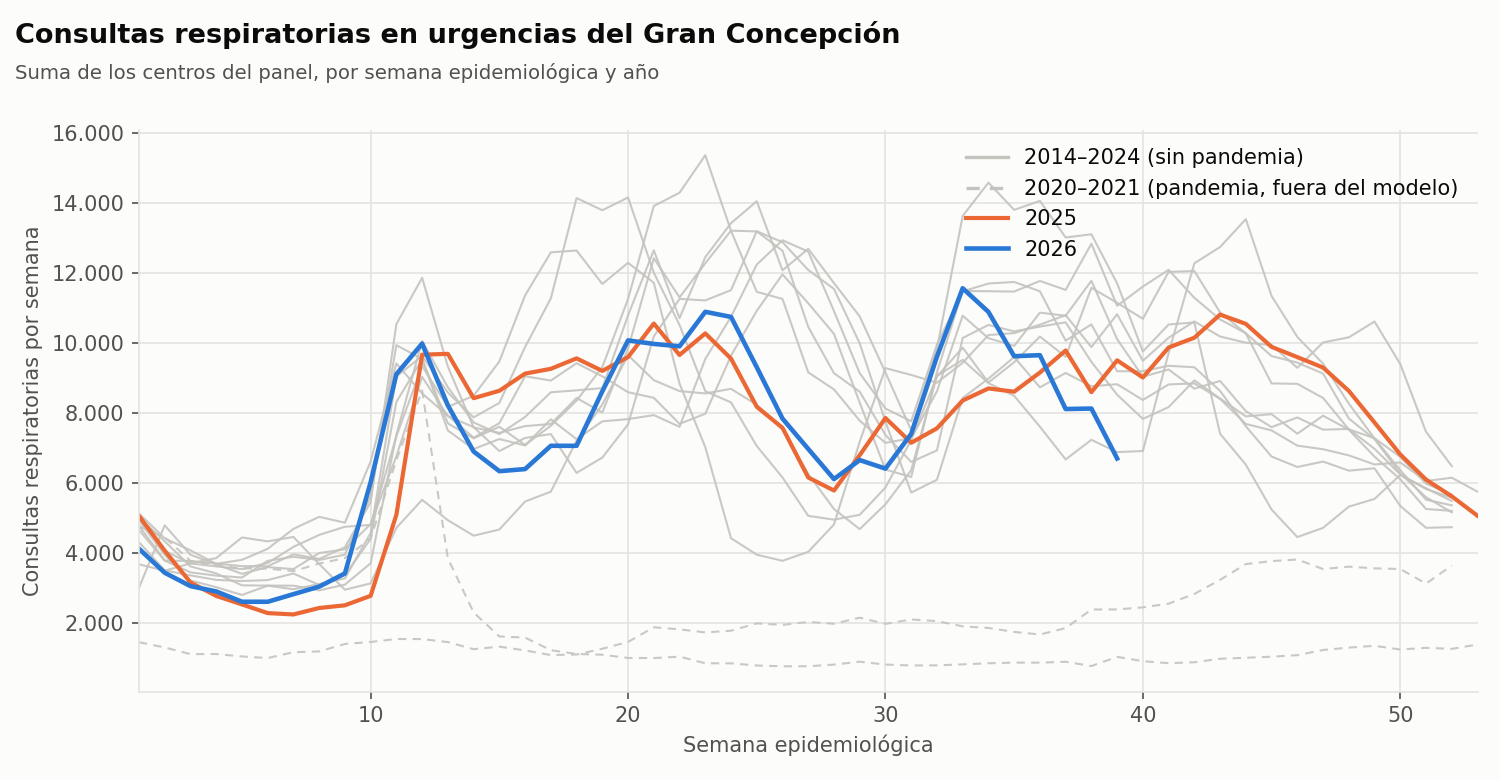

In [21]:
# Sin la última semana publicada si viene a medias (si no, parece una caída brusca)
completas = panel[panel["inicio_semana"] <= semana_de_referencia(panel)]
curva_estacional(completas, r.resultados / "fig1_curva_estacional.png", PRUEBA)
display(Image(r.resultados / "fig1_curva_estacional.png"))

### Centros con más consultas
**Qué buscar:** qué centros concentran la demanda. Son los candidatos naturales para la demo y para las entrevistas de validación.

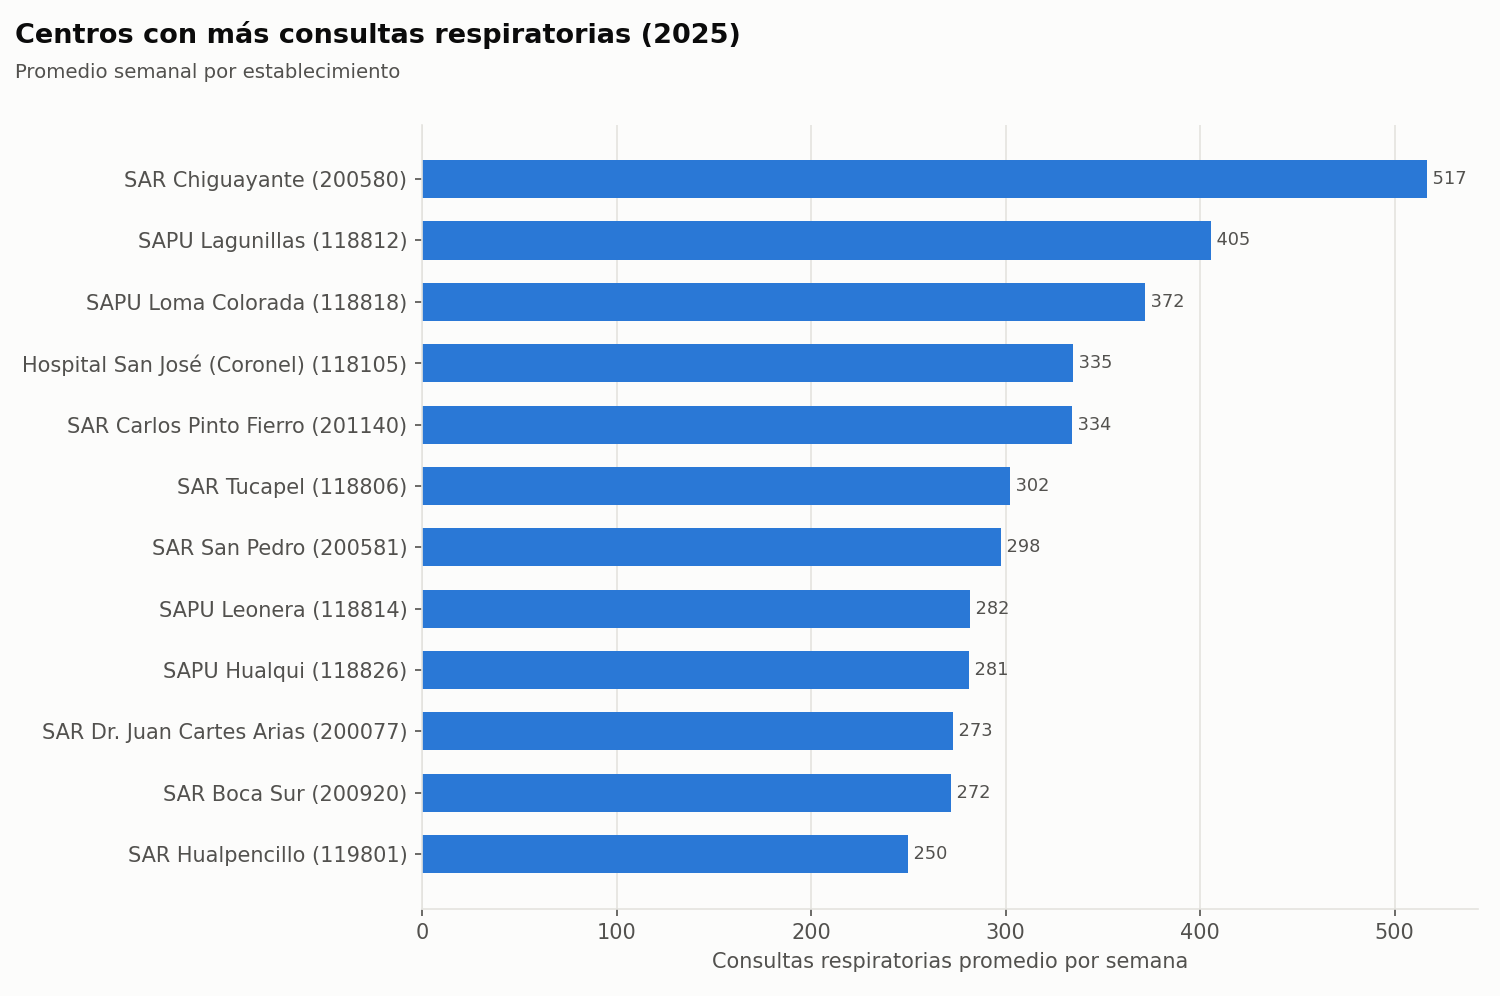

In [22]:
centros_principales(panel, r.resultados / "fig2_centros_principales.png", prueba=PRUEBA)
display(Image(r.resultados / "fig2_centros_principales.png"))

### Contaminación y consultas en el tiempo
Dos paneles con el mismo eje de tiempo (nunca un gráfico con dos ejes y). **Qué buscar:** si los peaks de MP2,5 coinciden con las alzas de consultas o las anteceden.

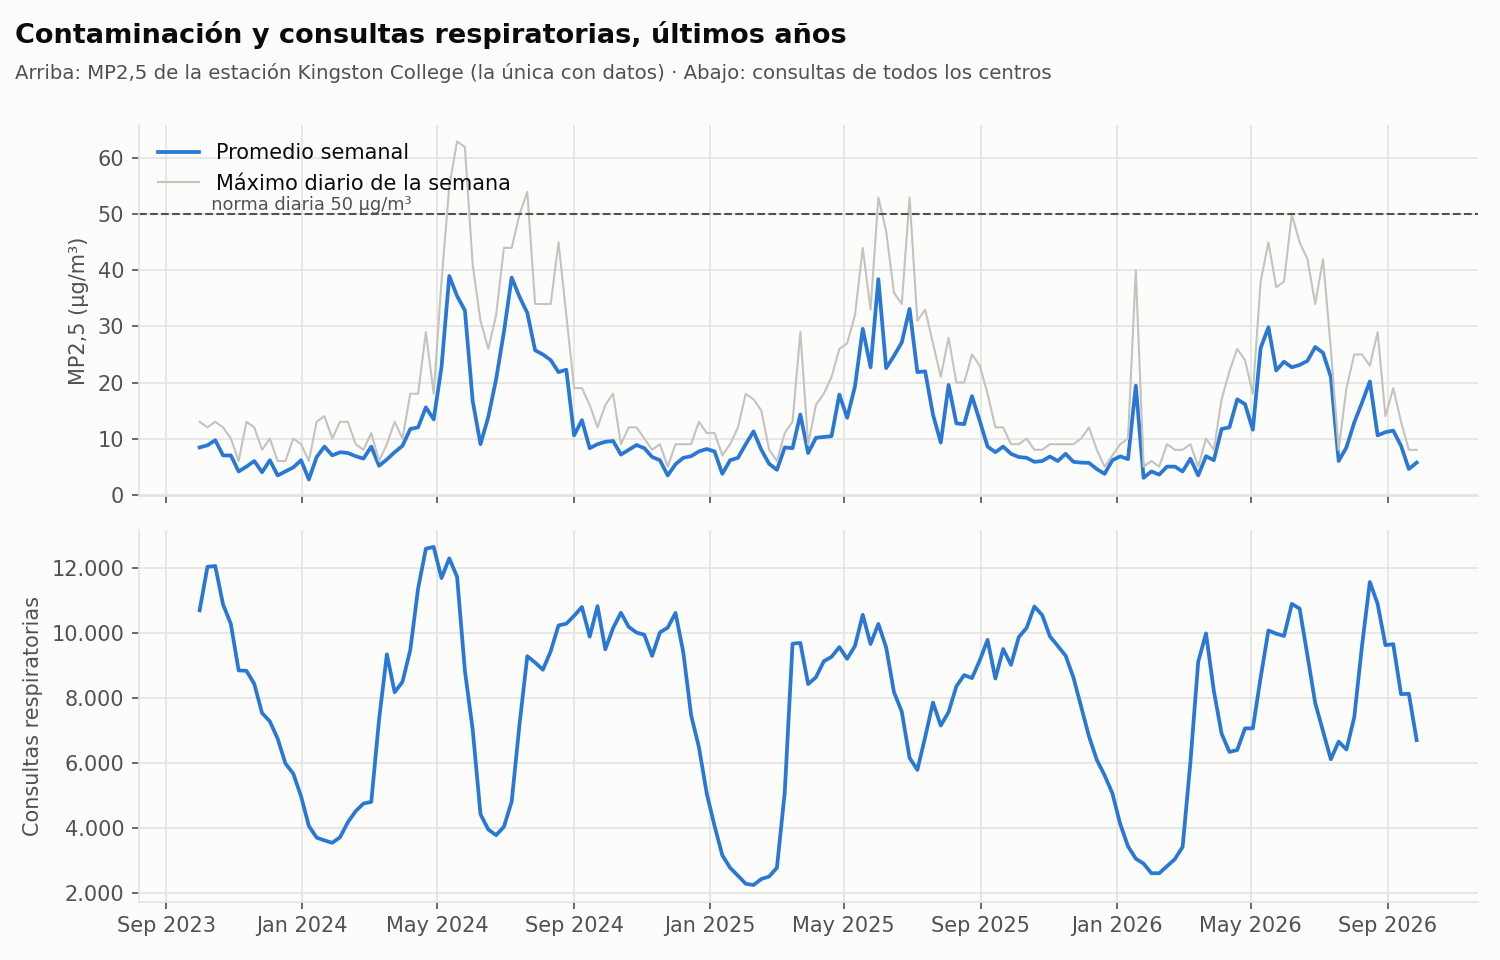

In [23]:
if panel["mp25"].notna().any():
    mp25_y_consultas(completas, r.resultados / "fig3_mp25_y_consultas.png", UMBRAL_DIARIO_MP25, prueba=PRUEBA)
    display(Image(r.resultados / "fig3_mp25_y_consultas.png"))

## 7. Modelo y validación

**Modelo:** regresión de Poisson con sobredispersión (cuasi-Poisson). Explica las consultas semanales de cada centro con:

- un efecto propio de cada centro (su tamaño),
- estacionalidad (senos y cosenos de la semana del año) y tendencia,
- consultas de las dos semanas anteriores y actividad viral de la semana anterior,
- MP2,5 y temperatura de la semana anterior, y en la versión `con_pronostico` también los de la semana pronosticada.

**Validación:** se entrena con los años anteriores a 2024 (sin 2020 y 2021) y se prueba desde 2024, años que el modelo no vio.

- `solo_rezagos` usa solo información disponible la semana anterior: es la evaluación **honesta**.
- `con_pronostico` usa el MP2,5 **observado** de la semana pronosticada como si fuera un pronóstico perfecto: es una cota **optimista**.
- Las **líneas base** son pronósticos ingenuos que el modelo debe superar para justificar su complejidad.

In [24]:
entrenamiento, prueba = dividir(panel)
prueba = prueba.assign(fila=prueba.index)
lim = umbrales(entrenamiento)
print(f"Entrenamiento: {len(entrenamiento):,} semanas-centro · Prueba: {len(prueba):,} semanas-centro")

predicciones, ajustes = {}, {}
for nombre, terminos in ESPECIFICACIONES.items():
    terminos = terminos_disponibles(panel, terminos)
    ajuste, _ = ajustar(entrenamiento, terminos)
    ajustes[nombre] = (ajuste, terminos)
    predicciones[nombre] = predecir(ajuste, prueba, terminos).merge(lim, on="estab")
    print(f"{nombre}: sobredispersión = {ajuste.scale:.1f}")

comunes = set.intersection(*(set(d["fila"]) for d in predicciones.values()))
base = predicciones["solo_rezagos"][lambda d: d["fila"].isin(comunes)]
filas = []
for nombre, d in predicciones.items():
    d = d[d["fila"].isin(comunes)]
    filas.append({"modelo": nombre, **metricas(d["y"], d["pred"]), **evaluar_alertas(d)})
for nombre, columna in {"base: semana anterior": "y_l1", "base: misma semana año anterior": "y_l52"}.items():
    d = base.assign(pred=base[columna]).dropna(subset=["pred"])
    filas.append({"modelo": nombre, **metricas(d["y"], d["pred"]), **evaluar_alertas(d)})
tabla_metricas = pd.DataFrame(filas).set_index("modelo")
tabla_metricas[["MAE", "WAPE_%", "sesgo_%", "precision", "sensibilidad", "F1", "alertas_emitidas", "semanas_altas_reales"]]

Entrenamiento: 12,066 semanas-centro · Prueba: 4,611 semanas-centro
solo_rezagos: sobredispersión = 9.3
con_pronostico: sobredispersión = 9.2


,MAE,WAPE_%,sesgo_%,precision,sensibilidad,F1,alertas_emitidas,semanas_altas_reales
modelo,,,,,,,,
solo_rezagos,35.48,14.86,-0.42,0.85,0.48,0.61,196,349
con_pronostico,34.94,14.64,-0.27,0.82,0.49,0.62,210,349
base: semana anterior,35.78,14.99,-0.09,0.69,0.68,0.69,347,349
base: misma semana año anterior,56.33,23.59,2.51,0.49,0.50,0.50,358,349


**Cómo leer la tabla**

- **MAE:** error promedio en consultas por semana. **WAPE:** error total como % de las consultas totales. Menor es mejor.
- **Sesgo:** negativo = el modelo subestima.
- **Precisión:** de las alertas emitidas, qué fracción fue una semana realmente alta. **Sensibilidad:** de las semanas realmente altas, qué fracción se alertó. **F1** combina ambas.
- Una "semana alta" es una semana con consultas sobre el percentil 90 del centro en sus últimos 3 años de entrenamiento (`ANIOS_UMBRAL`).

### Asociación entre MP2,5 y consultas
Cambio porcentual en las consultas por cada 10 µg/m³ adicionales, manteniendo constantes la estacionalidad, la temperatura, los virus y la demanda reciente. Es una **asociación**, no una prueba de causalidad.

In [25]:
efecto = efecto_mp25(ajustes["con_pronostico"][0])
for _, f in efecto.iterrows():
    cuando = "la misma semana" if f["termino"] == "mp25" else "la semana anterior"
    display(Markdown(f"- **{cuando}:** {f['cambio_%_por_10ug']:+.1f}% de consultas por cada 10 µg/m³ "
                     f"(IC 95%: {f['ic95_inf_%']:+.1f}% a {f['ic95_sup_%']:+.1f}%)"))
if PRUEBA:
    display(Markdown("*En los datos sintéticos el efecto real es +4,1% (misma semana) y +3,0% (semana anterior): "
                     "sirve para comprobar que el modelo lo recupera.*"))
efecto

- **la semana anterior:** -0.7% de consultas por cada 10 µg/m³ (IC 95%: -1.3% a -0.1%)

- **la misma semana:** +3.0% de consultas por cada 10 µg/m³ (IC 95%: +2.4% a +3.6%)

,termino,cambio_%_por_10ug,ic95_inf_%,ic95_sup_%,p_valor
0,mp25_l1,-0.71,-1.27,-0.14,0.01
1,mp25,3.01,2.43,3.59,0.00


### El efecto en un gráfico
Cambio esperado en las consultas cuando el MP2,5 se mantiene dos semanas seguidas en cierto nivel, comparado con una semana limpia (10 µg/m³) y con todo lo demás constante. La banda es el intervalo de confianza de 95 %. La curva cubre solo el rango de promedios semanales observado: la norma de 50 µg/m³ es **diaria**, y un promedio semanal de 50 casi no ocurre.

Ojo: en un gráfico simple de consultas vs MP2,5 esta relación casi no se ve, porque la tapan el frío y los brotes de virus, que suben al mismo tiempo. El modelo la separa al controlar esas variables.

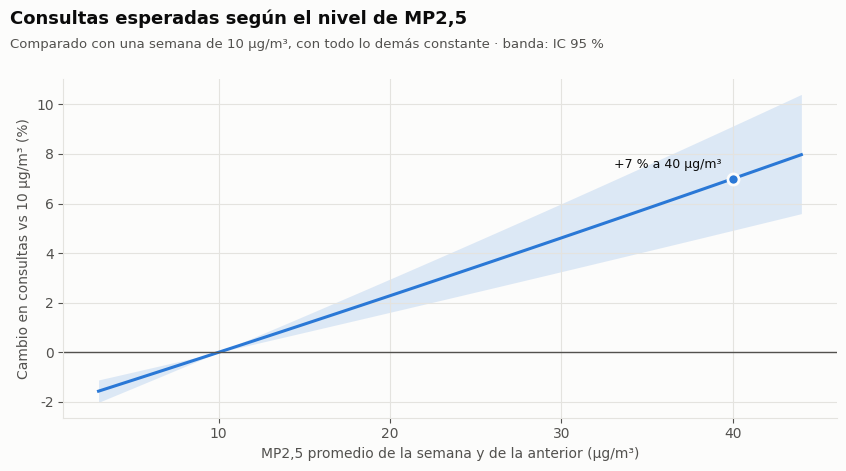

De una semana con 10 µg/m³ a una con 40 µg/m³: +7 % de consultas (IC 95 %: 4,9 a 9,1 %)


In [26]:
ajuste, _ = ajustes["con_pronostico"]
b = ajuste.params[["mp25", "mp25_l1"]].sum()
cov = ajuste.cov_params().loc[["mp25", "mp25_l1"], ["mp25", "mp25_l1"]].to_numpy().sum()
# Solo el rango de MP2,5 semanal que de verdad se observó (fuera de él sería extrapolar)
q01, q99 = panel["mp25"].quantile([0.01, 0.99])
niveles = np.arange(max(1, int(np.floor(q01))), int(np.ceil(q99)) + 1)
referencia = 10                      # una semana limpia
alto = int(min(40, np.floor(q99)))   # una semana mala, dentro de lo observado
delta = niveles - referencia
centro = 100 * (np.exp(b * delta) - 1)
inf = 100 * (np.exp((b - 1.96 * np.sqrt(cov)) * delta) - 1)
sup = 100 * (np.exp((b + 1.96 * np.sqrt(cov)) * delta) - 1)
cambio_alto = 100 * (np.exp(b * (alto - referencia)) - 1)

_estilo()
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.fill_between(niveles, np.minimum(inf, sup), np.maximum(inf, sup), color=COLORES["serie1"], alpha=0.15, linewidth=0)
ax.plot(niveles, centro, color=COLORES["serie1"], linewidth=2.2)
ax.axhline(0, color=COLORES["texto2"], linewidth=1)
ax.plot([alto], [cambio_alto], marker="o", markersize=8, color=COLORES["serie1"],
        markeredgecolor=COLORES["superficie"], markeredgewidth=2)
ax.annotate(f"{numero(cambio_alto, 1, signo=True)} % a {alto} µg/m³", xy=(alto, cambio_alto), xytext=(-8, 8),
            textcoords="offset points", ha="right", fontsize=9, color=COLORES["texto"])
_ejes_es(ax)
ax.set_xlabel("MP2,5 promedio de la semana y de la anterior (µg/m³)")
ax.set_ylabel(f"Cambio en consultas vs {referencia} µg/m³ (%)")
tope = _titulos(fig, "Consultas esperadas según el nivel de MP2,5",
                         f"Comparado con una semana de {referencia} µg/m³, con todo lo demás constante · banda: IC 95 %", PRUEBA)
fig.tight_layout(rect=(0, 0, 1, tope))
fig.savefig(r.resultados / "fig5_efecto_mp25.png", dpi=150)
plt.show()
print(f"De una semana con {referencia} µg/m³ a una con {alto} µg/m³: {numero(cambio_alto, 1, signo=True)} % de consultas "
      f"(IC 95 %: {numero(inf[niveles == alto][0], 1)} a {numero(sup[niveles == alto][0], 1)} %)")

### Todos los coeficientes (sin los efectos de cada centro)
`razon` = cuánto se multiplican las consultas por cada unidad de la variable. Por ejemplo, una razón de 1,02 en `log_viral_l1` significa que más actividad viral la semana anterior se asocia a más consultas.

In [27]:
ajuste, _ = ajustes["con_pronostico"]
ic = ajuste.conf_int()
coef = pd.DataFrame({"coeficiente": ajuste.params, "razon": np.exp(ajuste.params),
                     "ic95_inf": np.exp(ic[0]), "ic95_sup": np.exp(ic[1]), "p_valor": ajuste.pvalues})
coef[~coef.index.str.startswith("C(estab)")]

,coeficiente,razon,ic95_inf,ic95_sup,p_valor
Intercept,1.36,3.91,3.58,4.28,0.00
s1,-0.01,0.99,0.98,1.00,0.03
c1,-0.05,0.95,0.94,0.96,0.00
s2,-0.03,0.97,0.97,0.98,0.00
c2,-0.06,0.94,0.93,0.94,0.00
s3,-0.01,0.99,0.99,1.00,0.00
c3,-0.00,1.00,0.99,1.00,0.10
tendencia,-0.00,1.00,1.00,1.00,0.00
log_y_l1,0.85,2.33,2.29,2.38,0.00
log_y_l2,-0.08,0.93,0.91,0.94,0.00


In [28]:
d = predicciones["solo_rezagos"][lambda x: x["fila"].isin(comunes)].copy()
desv = (d["pred_sup"] - d["pred"]) / 1.645     # desviación del pronóstico
d["pred_1sd"] = d["pred"] + desv                # punto intermedio entre A y C

reglas = {
    "A · pronóstico (regla actual)": "pred",
    "B · pronóstico + 1 desviación": "pred_1sd",
    "C · límite superior del intervalo 90 %": "pred_sup",
}
filas = [{"regla": nombre, **evaluar_alertas(d, columna)} for nombre, columna in reglas.items()]
linea_base = d.assign(pred=d["y_l1"]).dropna(subset=["pred"])
filas.append({"regla": "Línea base · semana anterior", **evaluar_alertas(linea_base)})

prueba_regla = pd.DataFrame(filas).set_index("regla")
prueba_regla["cumple_meta"] = (prueba_regla["precision"] >= 0.70) & (prueba_regla["sensibilidad"] >= 0.60)
prueba_regla[["precision", "sensibilidad", "F1", "alertas_emitidas", "aciertos", "cumple_meta"]].round(2)

,precision,sensibilidad,F1,alertas_emitidas,aciertos,cumple_meta
regla,,,,,,
A · pronóstico (regla actual),0.85,0.48,0.61,196,166,False
B · pronóstico + 1 desviación,0.50,0.85,0.63,593,297,False
C · límite superior del intervalo 90 %,0.34,0.96,0.50,975,334,False
Línea base · semana anterior,0.69,0.68,0.69,347,239,False


In [29]:
for k in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0]:
    m = evaluar_alertas(d.assign(p=d["pred"] + k * desv), "p")
    print(f"k={k:.1f}  precisión={m['precision']:.2f}  sensibilidad={m['sensibilidad']:.2f}  F1={m['F1']:.2f}")

k=0.0  precisión=0.85  sensibilidad=0.48  F1=0.61
k=0.1  precisión=0.84  sensibilidad=0.53  F1=0.65
k=0.2  precisión=0.79  sensibilidad=0.58  F1=0.67
k=0.3  precisión=0.75  sensibilidad=0.61  F1=0.67
k=0.4  precisión=0.73  sensibilidad=0.66  F1=0.69
k=0.5  precisión=0.68  sensibilidad=0.70  F1=0.69
k=0.7  precisión=0.60  sensibilidad=0.76  F1=0.67
k=1.0  precisión=0.50  sensibilidad=0.85  F1=0.63


## 8. Backtest: ¿qué habría avisado el sistema el último invierno?
Cada semana se pronostica la siguiente con lo que se sabía hasta ese momento (modelo `solo_rezagos`). Los puntos naranjos son las semanas en que el sistema habría emitido alerta.

**Qué mirar:** si las alertas llegan antes o después del peak real. Un modelo basado en semanas anteriores tiende a reaccionar con algo de atraso ante alzas bruscas: es un buen tema para las iteraciones del proyecto.

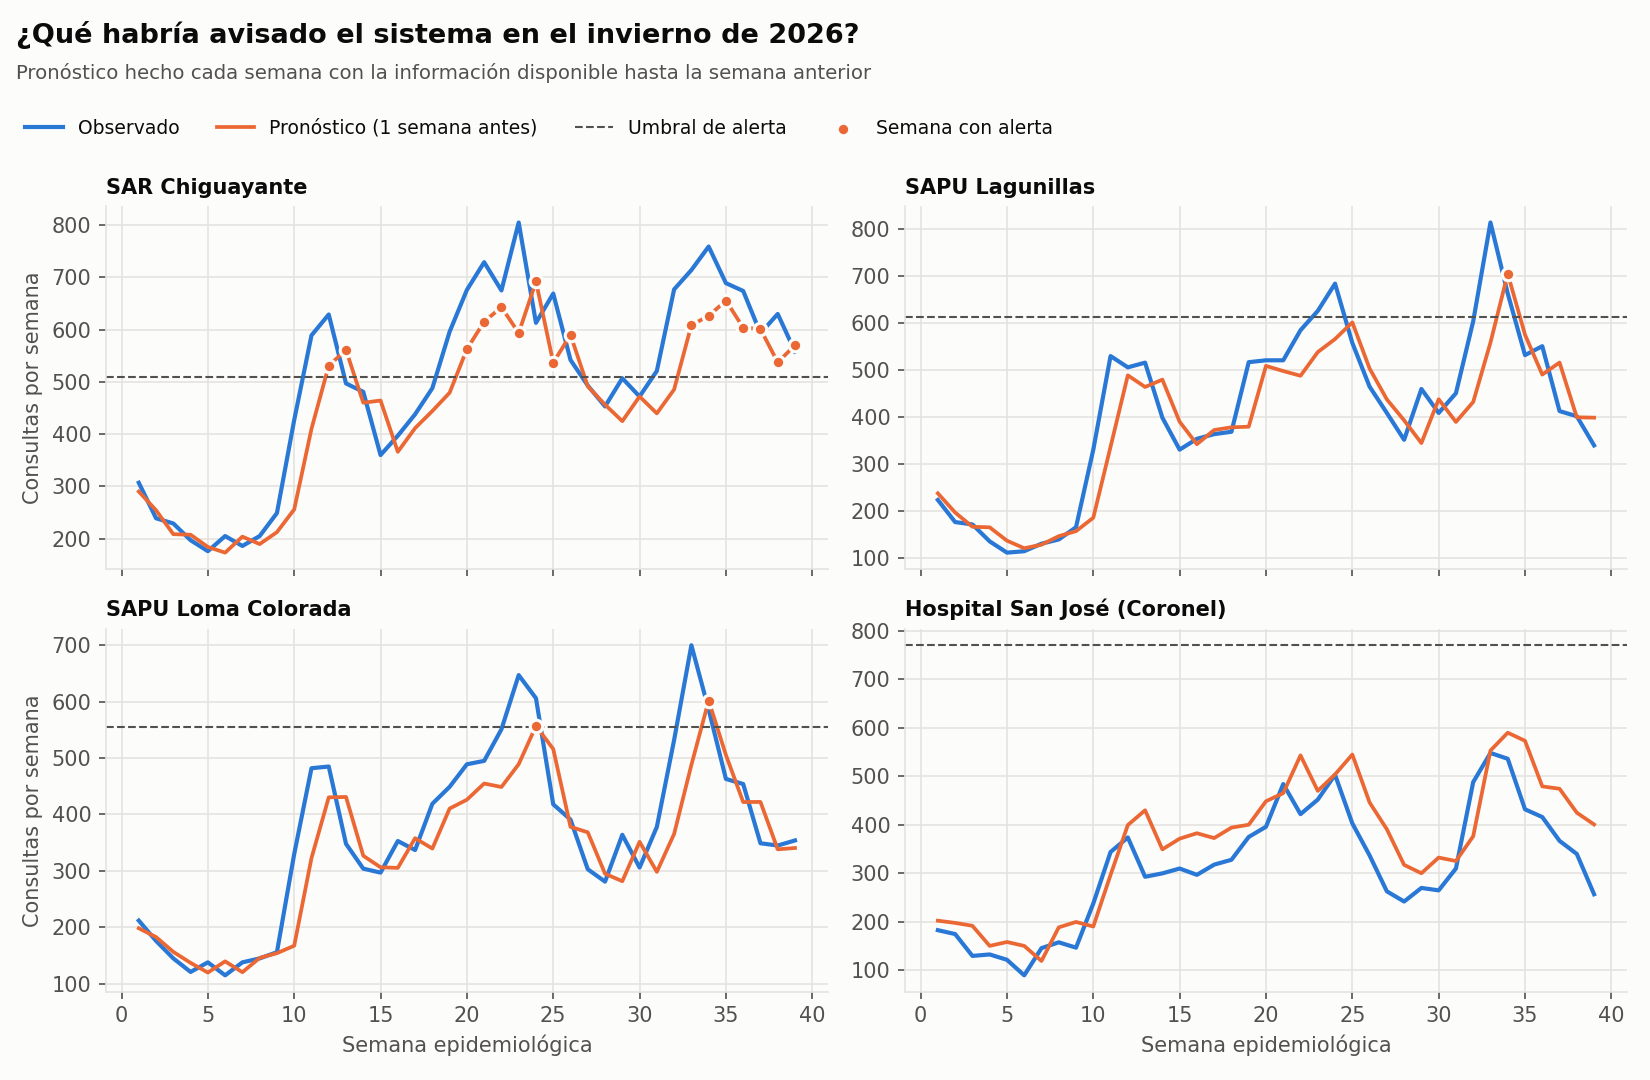

,Invierno 2026
alertas_emitidas,43.00
semanas_altas_reales,77.00
aciertos,39.00
precision,0.91
sensibilidad,0.51
F1,0.65


In [30]:
pred = predicciones["solo_rezagos"].copy()
pred["alerta"] = pred["pred"] > pred["umbral_alerta"]
con_invierno = pred[pred["semana"].isin(SEMANAS_INVIERNO)].groupby("anio")["semana"].nunique()
anio = int(con_invierno[con_invierno >= len(SEMANAS_INVIERNO) - 2].index.max())
inv = pred[(pred["anio"] == anio) & pred["semana"].isin(SEMANAS_INVIERNO)]
principales = inv.groupby("estab")["y"].sum().nlargest(4).index.tolist()

backtest(pred, r.resultados / "fig4_backtest_invierno.png", principales, anio, PRUEBA)
display(Image(r.resultados / "fig4_backtest_invierno.png"))
pd.Series(evaluar_alertas(inv), name=f"Invierno {anio}").to_frame()

## 9. Pronóstico de la próxima semana
Se reentrena el modelo con todos los datos válidos y se pronostica la semana siguiente a la última semana **completa**: si la última semana publicada viene con pocos centros o con un total anormalmente bajo, se usa la anterior y se avisa. El MP2,5 de la semana pronosticada viene del pronóstico de Open-Meteo; si no hay, se asume igual al último dato disponible.

Niveles: **atención** sobre el percentil 75 del centro en sus últimos 3 años, **ALERTA** sobre el percentil 90.

In [31]:
validos = panel[~panel["excluido"] & panel["estab"].isin(entrenamiento["estab"].unique())
                & (panel["inicio_semana"] <= semana_de_referencia(panel))]  # sin la semana a medias
terminos = terminos_disponibles(panel, ESPECIFICACIONES["con_pronostico"])
ajuste_final, _ = ajustar(validos, terminos)

mp25_pron, mp25_pron_max = None, None
if r.pronostico_mp25.exists():
    pron = pd.read_csv(r.pronostico_mp25, parse_dates=["fecha_hora"])
    diario = pron.groupby(pron["fecha_hora"].dt.date)["pm2_5"].mean()
    mp25_pron, mp25_pron_max = float(diario.mean()), float(diario.max())

base_sig = fila_proxima_semana(panel, mp25_pron)
base_sig = base_sig[base_sig["estab"].isin(validos["estab"])]
sig = predecir(ajuste_final, base_sig, terminos).merge(umbrales(validos), on="estab")
if sig.empty:
    display(faltantes(base_sig, terminos).to_frame("% sin dato"))
    raise RuntimeError("No se pudo pronosticar: revisen las variables con 100 % sin dato (tabla de arriba).")
semana_obj = sig["semana"].iloc[0]
recientes = validos[validos["anio"].isin(sorted(validos["anio"].unique())[-ANIOS_UMBRAL:])]
tipica = (recientes[recientes["semana"].between(semana_obj - 2, semana_obj + 2)]
          .groupby("estab")["y"].median().rename("y_semana_tipica"))
sig = sig.merge(tipica, on="estab", how="left")
sig["nivel"] = np.select([sig["pred"] > sig["umbral_alerta"], sig["pred"] > sig["umbral_atencion"]],
                         ["ALERTA", "atención"], "normal")

print(f"Semana {semana_obj} de {sig['anio'].iloc[0]} · MP2,5: {sig['origen_mp25'].iloc[0]}")
if mp25_pron_max is not None:
    estado = "ALERTA AMBIENTAL" if mp25_pron_max > UMBRAL_DIARIO_MP25 else "sin alerta ambiental"
    print(f"Máximo diario de MP2,5 pronosticado: {mp25_pron_max:.0f} µg/m³ → {estado}")
sig[["nombre_estab", "comuna", "pred", "pred_inf", "pred_sup", "y_semana_tipica", "umbral_alerta", "nivel"]].sort_values("pred", ascending=False)

  [aviso] la última semana publicada (2026-10-04) parece incompleta (29 centros); se pronostica a partir de la semana del 2026-09-27
Semana 40 de 2026 · MP2,5: pronóstico Open-Meteo (CAMS)
Máximo diario de MP2,5 pronosticado: 9 µg/m³ → sin alerta ambiental


,nombre_estab,comuna,pred,pred_inf,pred_sup,y_semana_tipica,umbral_alerta,nivel
26,SAR Chiguayante,Chiguayante,546.03,430.52,661.53,642.50,713.40,normal
10,SAPU Loma Colorada,San Pedro de la Paz,357.55,264.08,451.02,512.00,596.00,normal
6,SAPU Lagunillas,Coronel,347.71,255.54,439.89,516.00,584.70,normal
8,SAPU Leonera,Chiguayante,318.59,230.36,406.82,342.50,407.70,normal
3,SAR Tucapel,Concepción,314.39,226.75,402.04,403.00,429.50,normal
28,SAR Boca Sur,San Pedro de la Paz,304.67,218.39,390.95,330.00,392.40,normal
1,Hospital San José (Coronel),Coronel,302.44,216.47,388.40,460.00,545.60,normal
30,SAR Carlos Pinto Fierro,Coronel,299.19,213.68,384.69,378.50,504.40,normal
24,SAR Víctor Manuel Fernández,Concepción,282.98,199.82,366.13,310.00,358.80,normal
0,Hospital Clínico Regional Dr. Guillermo Grant ...,Concepción,261.00,181.14,340.85,306.00,360.00,normal


### ¿Algún centro subió su última semana incompleta?
El pronóstico se apoya mucho en la semana anterior. Si un centro todavía no carga todos sus datos de esa semana, su pronóstico sale demasiado bajo. La tabla muestra la última semana completa dividida por la mediana de las 4 anteriores: **0,5 o menos** sugiere carga atrasada (conviene esperar a que el Minsal actualice); una baja moderada puede ser real.

In [32]:
ult = panel[panel["inicio_semana"] <= semana_de_referencia(panel)]
tabla = ult.pivot_table(index="nombre_estab", columns="inicio_semana", values="y").iloc[:, -6:]
s = tabla.columns
tabla["ultima / previas"] = (tabla[s[-1]] / tabla[s[-5:-1]].median(axis=1)).round(2)
tabla.columns = [c.strftime("%d-%m") if hasattr(c, "strftime") else c for c in tabla.columns]
tabla.sort_values("ultima / previas").head(10)

,23-08,30-08,06-09,13-09,20-09,27-09,ultima / previas
nombre_estab,,,,,,,
SAPU Alcalde Leocán Portus,242.00,241.00,218.00,209.00,200.00,87.00,0.41
SAPU Talcahuano Sur,269.00,235.00,282.00,222.00,217.00,99.00,0.43
SAPU Paulina Avendaño Pereda,108.00,68.00,113.00,106.00,124.00,68.00,0.62
SAR San Pedro,454.00,438.00,387.00,376.00,332.00,237.00,0.62
SAPU Lorenzo Arenas,254.00,238.00,247.00,199.00,239.00,158.00,0.66
Hospital San José (Coronel),536.00,432.00,416.00,367.00,340.00,257.00,0.66
SAR Dr. Juan Cartes Arias,417.00,362.00,355.00,344.00,300.00,233.00,0.67
SAPU La Floresta,272.00,225.00,246.00,203.00,231.00,152.00,0.67
Hospital de Tomé,115.00,100.00,125.00,93.00,93.00,66.00,0.68


## 10. Dotación con teoría de colas (Erlang C)

Modelo **M/M/c**: los pacientes llegan al azar a una tasa $\lambda$ por hora, cada profesional atiende en promedio en $1/\mu$ minutos, y hay $c$ profesionales con una sola fila. Con $a = \lambda/\mu$, la probabilidad de esperar es la fórmula de Erlang C:

$$P_{espera} = \frac{\frac{a^c}{c!}\frac{c}{c-a}}{\sum_{k=0}^{c-1}\frac{a^k}{k!} + \frac{a^c}{c!}\frac{c}{c-a}}, \qquad W_q = \frac{P_{espera}}{c\mu - \lambda}$$

Se busca el menor $c$ que mantiene la espera media $W_q$ bajo el objetivo. Los parámetros están en la configuración (A1) y son **supuestos a validar en las entrevistas**.

In [33]:
def calcular(consultas_semana):
    lam = llegadas_hora_punta(consultas_semana, HORAS_FUNCIONAMIENTO_SEMANA, FACTOR_HORA_PUNTA)
    return lam, dotacion_minima(lam, MINUTOS_POR_ATENCION, ESPERA_OBJETIVO_MIN)

filas = []
for _, f in sig.iterrows():
    lam_t, c_t = calcular(f["y_semana_tipica"])
    lam_p, c_p = calcular(f["pred"])
    filas.append({"centro": f["nombre_estab"], "nivel": f["nivel"],
                  "llegadas_hora_punta": lam_p, "profesionales_semana_tipica": c_t,
                  "profesionales_necesarios": c_p, "refuerzo": max(c_p - c_t, 0),
                  "espera_sin_refuerzo_min": espera_media_min(c_t, lam_p, MINUTOS_POR_ATENCION)})
print(f"Supuestos: {MINUTOS_POR_ATENCION} min por atención · factor hora punta {FACTOR_HORA_PUNTA} · "
      f"espera objetivo {ESPERA_OBJETIVO_MIN} min")
pd.DataFrame(filas).sort_values("llegadas_hora_punta", ascending=False)

Supuestos: 15 min por atención · factor hora punta 1.6 · espera objetivo 30 min


,centro,nivel,llegadas_hora_punta,profesionales_semana_tipica,profesionales_necesarios,refuerzo,espera_sin_refuerzo_min
26,SAR Chiguayante,normal,5.20,2,2,0,10.98
10,SAPU Loma Colorada,normal,3.41,2,2,0,3.32
6,SAPU Lagunillas,normal,3.31,2,2,0,3.10
8,SAPU Leonera,normal,3.03,2,2,0,2.52
3,SAR Tucapel,normal,2.99,2,2,0,2.44
28,SAR Boca Sur,normal,2.90,2,2,0,2.27
1,Hospital San José (Coronel),normal,2.88,2,2,0,2.23
30,SAR Carlos Pinto Fierro,normal,2.85,2,2,0,2.18
24,SAR Víctor Manuel Fernández,normal,2.70,2,2,0,1.92
0,Hospital Clínico Regional Dr. Guillermo Grant ...,normal,2.49,2,1,0,1.60


### ¿Qué tan sensible es la dotación a los supuestos?
Espera media en hora punta del centro con más demanda, según cuántos profesionales atienden. Con menos profesionales que llegadas por hora × horas por atención, la fila crece sin límite; con uno más, la espera cae bruscamente.

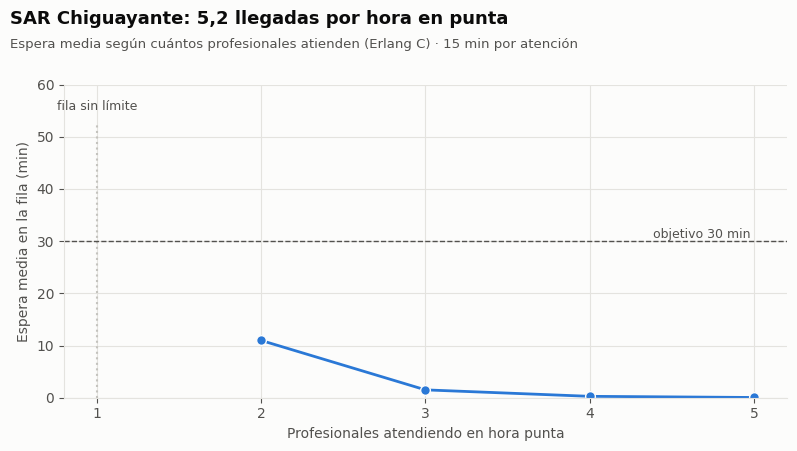

,10 min/atención,15 min/atención,20 min/atención
espera objetivo 15 min,2,2,3
espera objetivo 30 min,2,2,3
espera objetivo 60 min,2,2,3


In [34]:
mayor = sig.sort_values("pred").iloc[-1]
lam = llegadas_hora_punta(mayor["pred"], HORAS_FUNCIONAMIENTO_SEMANA, FACTOR_HORA_PUNTA)
c_min = int(np.ceil(lam * MINUTOS_POR_ATENCION / 60))  # con menos, la fila crece sin límite
cs = list(range(max(1, c_min - 1), c_min + 4))
esperas = [espera_media_min(c, lam, MINUTOS_POR_ATENCION) for c in cs]
techo = 2 * max(ESPERA_OBJETIVO_MIN, max(e for e in esperas if np.isfinite(e)))

_estilo()
fig, ax = plt.subplots(figsize=(8, 4.6))
finitos = [(c, e) for c, e in zip(cs, esperas) if np.isfinite(e)]
ax.plot(*zip(*finitos), color=COLORES["serie1"], linewidth=2, marker="o", markersize=7,
        markeredgecolor=COLORES["superficie"])
for c, e in zip(cs, esperas):
    if not np.isfinite(e):
        ax.annotate("fila sin límite", xy=(c, techo * 0.92), ha="center", fontsize=9, color=COLORES["texto2"])
        ax.plot([c, c], [0, techo * 0.88], color=COLORES["contexto"], linewidth=1.5, linestyle=":")
ax.set_ylim(0, techo)
ax.axhline(ESPERA_OBJETIVO_MIN, color=COLORES["texto2"], linewidth=1, linestyle="--")
ax.text(cs[-1], ESPERA_OBJETIVO_MIN, f"objetivo {ESPERA_OBJETIVO_MIN} min ", ha="right",
        va="bottom", fontsize=9, color=COLORES["texto2"])
ax.set_xticks(cs)
ax.set_xlabel("Profesionales atendiendo en hora punta")
ax.set_ylabel("Espera media en la fila (min)")
_ejes_es(ax)
tope = _titulos(fig, f"{mayor['nombre_estab']}: {numero(lam, 1)} llegadas por hora en punta",
                         f"Espera media según cuántos profesionales atienden (Erlang C) · {MINUTOS_POR_ATENCION} min por atención",
                         PRUEBA)
fig.tight_layout(rect=(0, 0, 1, tope))
fig.savefig(r.resultados / "fig6_dotacion.png", dpi=150)
plt.show()

sensibilidad = pd.DataFrame(
    {f"{mins} min/atención": [dotacion_minima(lam, mins, obj) for obj in (15, 30, 60)] for mins in (10, 15, 20)},
    index=["espera objetivo 15 min", "espera objetivo 30 min", "espera objetivo 60 min"])
sensibilidad

## 11. Antes de usar estos resultados

- [ ] Las columnas detectadas coinciden con los diccionarios de datos.
- [ ] Ninguna causa quedó como `no_clasificada` y las causas de `y` suman cerca del 100 % del total respiratorio.
- [ ] Los centros del Gran Concepción son los esperados y la unión de códigos calzó casi completa.
- [ ] Cada comuna tiene su estación de SINCA con datos (completar códigos en `config.ESTACIONES`).
- [ ] El modelo supera a las dos líneas base en WAPE y F1.
- [ ] El efecto del MP2,5 se reporta como asociación, con su intervalo de confianza.
- [ ] Los supuestos de dotación (minutos por atención, hora punta, espera objetivo) se validaron en entrevistas.
- [ ] Se verificó con qué atraso publica el Minsal los datos semanales.

,pesos actuales,pesos iguales,Power BI ya pagado
ALT-1 · reglas fijas,3.80,4.00,3.80
ALT-2 · web propia,4.40,4.40,4.40
ALT-3 · Power BI,2.40,2.20,3.00


,ALT-1 · reglas fijas,ALT-2 · web propia,ALT-3 · Power BI
peso de precisión (%),,,
5,4.55,4.24,1.71
10,4.36,4.28,1.88
15,4.17,4.32,2.05
20,3.99,4.36,2.23
25,3.80,4.40,2.40
30,3.61,4.44,2.57
35,3.43,4.48,2.75


ALT-2 gana desde un peso de precisión de 11,8 %; bajo eso gana ALT-1.


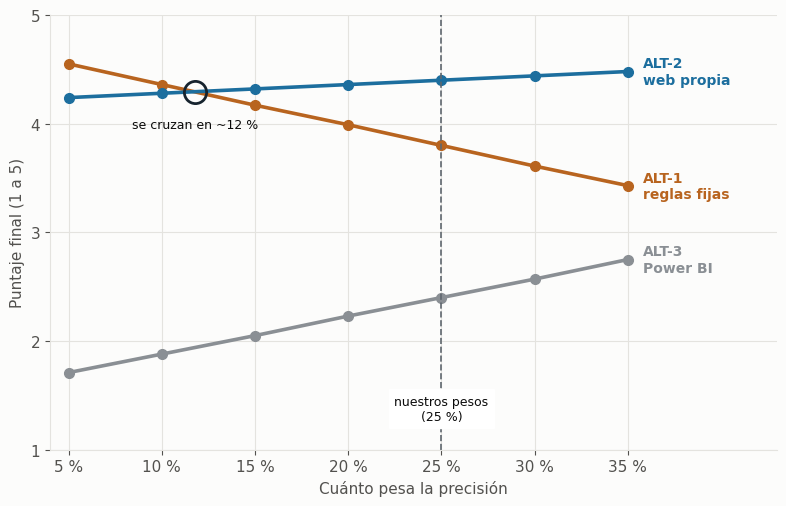

Guardado en: c:\Users\mario\Desktop\Proyecto Informatico\resultados\fig_sensibilidad_matriz.png


In [35]:
# %% [markdown]
# ## Análisis de sensibilidad de la matriz de decisión (E2)
# ¿La decisión cambia si cambiamos cuánto pesa cada criterio?
#
# Se mueve el peso de **precisión** entre 5 % y 35 % y el resto se reparte
# entre los demás criterios en proporción a sus pesos originales.
# Si Juan cambia un peso o un puntaje de la matriz, se corrige aquí y se vuelve a correr.

# %%
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

# ---------------------------------------------------------------------------
# Matriz de decisión: debe coincidir con la lámina de la matriz
# ---------------------------------------------------------------------------
PESOS = {
    "precisión": 0.25,
    "factibilidad": 0.20,
    "autonomía": 0.20,
    "costo": 0.15,
    "usabilidad": 0.20,
}
PUNTAJES = {  # escala 1 a 5
    "ALT-1 · reglas fijas": {"precisión": 1, "factibilidad": 5, "autonomía": 5, "costo": 5, "usabilidad": 4},
    "ALT-2 · web propia":   {"precisión": 5, "factibilidad": 3, "autonomía": 5, "costo": 5, "usabilidad": 4},
    "ALT-3 · Power BI":     {"precisión": 5, "factibilidad": 2, "autonomía": 1, "costo": 1, "usabilidad": 2},
}
COLORES = {
    "ALT-1 · reglas fijas": "#B8641F",  # naranjo
    "ALT-2 · web propia":   "#1C6E9E",  # azul (la elegida)
    "ALT-3 · Power BI":     "#8A8F94",  # gris
}
CRITERIO = "precisión"  # el peso que se mueve


def total(puntajes: dict, pesos: dict) -> float:
    """Puntaje ponderado: suma de peso × puntaje."""
    return sum(pesos[c] * puntajes[c] for c in pesos)


def pesos_con(peso_nuevo: float, criterio: str = CRITERIO, pesos: dict = PESOS) -> dict:
    """Fija el peso de un criterio y reparte el resto en proporción a los pesos originales."""
    resto_original = 1 - pesos[criterio]
    return {c: (peso_nuevo if c == criterio else pesos[c] * (1 - peso_nuevo) / resto_original)
            for c in pesos}


def numero(valor: float, decimales: int = 2) -> str:
    """Número en formato chileno: coma decimal."""
    return f"{valor:.{decimales}f}".replace(".", ",")


# %%
# 1) Totales con los pesos actuales y los escenarios de la lámina
pesos_iguales = {c: 1 / len(PESOS) for c in PESOS}
puntajes_powerbi_pagado = {**PUNTAJES, "ALT-3 · Power BI": {**PUNTAJES["ALT-3 · Power BI"], "costo": 5}}

escenarios = pd.DataFrame({
    "pesos actuales": {a: total(p, PESOS) for a, p in PUNTAJES.items()},
    "pesos iguales": {a: total(p, pesos_iguales) for a, p in PUNTAJES.items()},
    "Power BI ya pagado": {a: total(p, PESOS) for a, p in puntajes_powerbi_pagado.items()},
}).round(2)
display(escenarios)

# %%
# 2) Barrido del peso de precisión (estos son los datos del gráfico)
pesos_prueba = np.round(np.arange(0.05, 0.351, 0.05), 2)
barrido = pd.DataFrame(
    {a: [total(p, pesos_con(w)) for w in pesos_prueba] for a, p in PUNTAJES.items()},
    index=pd.Index((pesos_prueba * 100).astype(int), name="peso de precisión (%)"),
).round(2)
display(barrido)

# 3) Punto donde ALT-1 y ALT-2 se cruzan (búsqueda fina)
fino = np.linspace(0.01, 0.50, 4901)
diferencia = np.array([total(PUNTAJES["ALT-2 · web propia"], pesos_con(w))
                       - total(PUNTAJES["ALT-1 · reglas fijas"], pesos_con(w)) for w in fino])
gana_alt2 = np.where(diferencia >= 0)[0]
cruce = fino[gana_alt2[0]] if len(gana_alt2) else None
if cruce is not None:
    print(f"ALT-2 gana desde un peso de precisión de {numero(100 * cruce, 1)} %; bajo eso gana ALT-1.")

# %%
# 4) Gráfico
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 5.2))
x = pesos_prueba * 100

for alt in PUNTAJES:
    ax.plot(x, barrido[alt], color=COLORES[alt], linewidth=2.6, marker="o", markersize=7)
    nombre, detalle = alt.split(" · ")
    ax.text(x[-1] + 0.8, barrido[alt].iloc[-1], f"{nombre}\n{detalle}",
            color=COLORES[alt], fontweight="bold", va="center", fontsize=10)

peso_actual = 100 * PESOS[CRITERIO]
ax.axvline(peso_actual, color="#5F676E", linestyle="--", linewidth=1.2)
ax.text(peso_actual, 1.25, f"nuestros pesos\n({numero(peso_actual, 0)} %)",
        ha="center", va="bottom", fontsize=9, backgroundcolor="white")

if cruce is not None:
    y_cruce = total(PUNTAJES["ALT-2 · web propia"], pesos_con(cruce))
    ax.plot(100 * cruce, y_cruce, marker="o", markersize=16, markerfacecolor="none",
            markeredgecolor="#16232E", markeredgewidth=2)
    ax.annotate(f"se cruzan en ~{numero(100 * cruce, 0)} %", (100 * cruce, y_cruce),
                xytext=(0, -26), textcoords="offset points", ha="center", fontsize=9)

ax.set_xlim(4, 43)
ax.set_ylim(1, 5)
ax.set_xticks(x)
ax.set_yticks(range(1, 6))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: numero(v, 0)))
ax.set_xlabel("Cuánto pesa la precisión")
ax.set_ylabel("Puntaje final (1 a 5)")
ax.grid(axis="y", color="#E4E3DF")
#ax.set_title("¿La decisión cambia si cambiamos la importancia de cada criterio?",
             #loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()

# Se guarda en la carpeta de resultados del notebook si existe; si no, en la carpeta actual
carpeta = r.resultados if "r" in globals() and hasattr(r, "resultados") else Path(".")
ruta = Path(carpeta) / "fig_sensibilidad_matriz.png"
fig.savefig(ruta, dpi=300)
plt.show()
print("Guardado en:", ruta)

In [36]:
# Sensibilidad de la matriz (versión 6 criterios). Se mueve el peso de "calendario",
# el criterio donde ALT-2 es más débil, y el resto se reparte en proporción.
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

PESOS = {"precisión": .25, "calendario": .20, "demo": .20, "usabilidad": .15, "costo": .10, "mantenibilidad": .10}
PUNTAJES = {
    "ALT-1 · reglas fijas":    dict(zip(PESOS, [3, 5, 5, 2, 5, 2])),
    "ALT-2 · motor propio":    dict(zip(PESOS, [5, 3, 5, 5, 4, 5])),
    "ALT-3 · Power BI":        dict(zip(PESOS, [5, 3, 1, 3, 2, 2])),
}
COLORES = {"ALT-1 · reglas fijas": "#B8641F", "ALT-2 · motor propio": "#1C6E9E", "ALT-3 · Power BI": "#8A8F94"}
CRITERIO = "calendario"

total = lambda p, w: sum(w[c] * p[c] for c in w)
def pesos_con(wn, c=CRITERIO):
    r = 1 - PESOS[c]
    return {k: (wn if k == c else PESOS[k] * (1 - wn) / r) for k in PESOS}
num = lambda v, d=2: f"{v:.{d}f}".replace(".", ",")

x = np.arange(0.05, 0.501, 0.05)
fino = np.linspace(0.01, 0.9, 8901)
dif = [total(PUNTAJES["ALT-2 · motor propio"], pesos_con(w)) - total(PUNTAJES["ALT-1 · reglas fijas"], pesos_con(w)) for w in fino]
cruce = next(w for w, d in zip(fino, dif) if d < 0)
print("ALT-1 gana si calendario pesa más de", num(100 * cruce, 1), "%")

plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 5.2))
for a, p in PUNTAJES.items():
    y = [total(p, pesos_con(w)) for w in x]
    ax.plot(100 * x, y, color=COLORES[a], lw=2.6, marker="o", ms=7)
    n, d = a.split(" · ")
    desfase = {"ALT-1": 0.18, "ALT-2": -0.2}.get(n, 0)
    ax.text(100 * x[-1] + 1.2, y[-1] + desfase, f"{n}\n{d}", color=COLORES[a], fontweight="bold", va="center", fontsize=12)
ax.axvline(20, color="#5F676E", ls="--", lw=1.2)
ax.text(20, 1.25, "nuestros pesos\n(20 %)", ha="center", va="bottom", fontsize=11, backgroundcolor="white")
yc = total(PUNTAJES["ALT-2 · motor propio"], pesos_con(cruce))
ax.plot(100 * cruce, yc, marker="o", ms=16, mfc="none", mec="#16232E", mew=2)
ax.annotate(f"se cruzan en ~{num(100*cruce,0)} %", (100 * cruce, yc), xytext=(0, 18), textcoords="offset points", ha="center", fontsize=11)
ax.set_xlim(3, 62); ax.set_ylim(1, 5); ax.set_xticks(100 * x); ax.set_yticks(range(1, 6))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlabel("Cuánto pesa el calendario"); ax.set_ylabel("Puntaje final (1 a 5)")
ax.grid(axis="y", color="#E4E3DF"); fig.tight_layout()
fig.savefig("grafico_sensibilidad_calendario.png", dpi=300)

ALT-1 gana si calendario pesa más de 41,8 %


In [37]:
# %% [markdown]
# ## Análisis de sensibilidad de la matriz de decisión (E2, versión 6 criterios)
# ¿La decisión cambia si cambiamos cuánto pesa cada criterio?
#
# Se mueve el peso del **calendario** (el criterio donde ALT-2 es más débil: 3 contra 5 de ALT-1)
# entre 5 % y 50 %, y el resto se reparte entre los demás criterios en proporción a sus pesos.
# Si cambia un peso o un puntaje de la lámina de la matriz, se corrige aquí y se vuelve a correr.

# %%
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

# ---------------------------------------------------------------------------
# Matriz de decisión: debe coincidir con la lámina "Matriz"
# ---------------------------------------------------------------------------
PESOS = {
    "precisión": 0.25,
    "calendario": 0.20,
    "demo en vivo": 0.20,
    "usabilidad": 0.15,
    "costo": 0.10,
    "mantenibilidad": 0.10,
}
PUNTAJES = {  # escala 1 a 5, en el mismo orden que PESOS
    "ALT-1 · reglas fijas": dict(zip(PESOS, [3, 5, 5, 2, 5, 2])),
    "ALT-2 · motor propio": dict(zip(PESOS, [5, 3, 5, 5, 4, 5])),
    "ALT-3 · Power BI":     dict(zip(PESOS, [5, 3, 1, 3, 2, 2])),
}
COLORES = {
    "ALT-1 · reglas fijas": "#B8641F",  # naranjo
    "ALT-2 · motor propio": "#1C6E9E",  # azul (la elegida)
    "ALT-3 · Power BI":     "#8A8F94",  # gris
}
CRITERIO = "calendario"  # el peso que se mueve


def total(puntajes: dict, pesos: dict) -> float:
    """Puntaje ponderado: suma de peso × puntaje."""
    return sum(pesos[c] * puntajes[c] for c in pesos)


def pesos_con(peso_nuevo: float, criterio: str = CRITERIO, pesos: dict = PESOS) -> dict:
    """Fija el peso de un criterio y reparte el resto en proporción a los pesos originales."""
    resto_original = 1 - pesos[criterio]
    return {c: (peso_nuevo if c == criterio else pesos[c] * (1 - peso_nuevo) / resto_original)
            for c in pesos}


def numero(valor: float, decimales: int = 2) -> str:
    """Número en formato chileno: coma decimal."""
    return f"{valor:.{decimales}f}".replace(".", ",")


# %%
# 1) Totales con los pesos actuales y los escenarios de la lámina
pesos_iguales = {c: 1 / len(PESOS) for c in PESOS}
powerbi_pagado = {**PUNTAJES, "ALT-3 · Power BI": {**PUNTAJES["ALT-3 · Power BI"], "costo": 5}}
alt1_precision_5 = {**PUNTAJES, "ALT-1 · reglas fijas": {**PUNTAJES["ALT-1 · reglas fijas"], "precisión": 5}}
alt2_calendario_1 = {**PUNTAJES, "ALT-2 · motor propio": {**PUNTAJES["ALT-2 · motor propio"], "calendario": 1}}

escenarios = pd.DataFrame({
    "pesos actuales": {a: total(p, PESOS) for a, p in PUNTAJES.items()},
    "pesos iguales": {a: total(p, pesos_iguales) for a, p in PUNTAJES.items()},
    "Power BI ya pagado": {a: total(p, PESOS) for a, p in powerbi_pagado.items()},
    "ALT-1 con precisión 5": {a: total(p, PESOS) for a, p in alt1_precision_5.items()},
    "ALT-2 con calendario 1": {a: total(p, PESOS) for a, p in alt2_calendario_1.items()},
}).round(2)
display(escenarios)

# %%
# 2) Barrido del peso del calendario (estos son los datos del gráfico)
pesos_prueba = np.round(np.arange(0.05, 0.501, 0.05), 2)
barrido = pd.DataFrame(
    {a: [total(p, pesos_con(w)) for w in pesos_prueba] for a, p in PUNTAJES.items()},
    index=pd.Index((pesos_prueba * 100).astype(int), name="peso del calendario (%)"),
).round(2)
display(barrido)

# 3) Punto donde ALT-1 pasa a ALT-2 (búsqueda fina)
fino = np.linspace(0.01, 0.90, 8901)
diferencia = np.array([total(PUNTAJES["ALT-2 · motor propio"], pesos_con(w))
                       - total(PUNTAJES["ALT-1 · reglas fijas"], pesos_con(w)) for w in fino])
gana_alt1 = np.where(diferencia < 0)[0]
cruce = fino[gana_alt1[0]] if len(gana_alt1) else None
if cruce is not None:
    print(f"ALT-1 gana solo si el calendario pesa más de {numero(100 * cruce, 1)} % (hoy pesa {numero(100 * PESOS[CRITERIO], 0)} %).")

# 4) ¿Algún otro criterio, por sí solo, cambia la decisión?
for c in PESOS:
    gana = [w for w in fino if total(PUNTAJES["ALT-2 · motor propio"], pesos_con(w, c))
            < total(PUNTAJES["ALT-1 · reglas fijas"], pesos_con(w, c))]
    print(f"{c:15s}: " + (f"ALT-1 gana desde {numero(100 * min(gana), 1)} %" if gana else "ALT-2 gana con cualquier peso"))

# %%
# 5) Gráfico
plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 5.2))
x = pesos_prueba * 100
desfase = {"ALT-1 · reglas fijas": 0.18, "ALT-2 · motor propio": -0.20}  # separa las etiquetas

for alt in PUNTAJES:
    ax.plot(x, barrido[alt], color=COLORES[alt], linewidth=2.6, marker="o", markersize=7)
    nombre, detalle = alt.split(" · ")
    ax.text(x[-1] + 1.2, barrido[alt].iloc[-1] + desfase.get(alt, 0), f"{nombre}\n{detalle}",
            color=COLORES[alt], fontweight="bold", va="center", fontsize=12)

peso_actual = 100 * PESOS[CRITERIO]
ax.axvline(peso_actual, color="#5F676E", linestyle="--", linewidth=1.2)
ax.text(peso_actual, 1.25, f"nuestros pesos\n({numero(peso_actual, 0)} %)",
        ha="center", va="bottom", fontsize=11, backgroundcolor="white")

if cruce is not None:
    y_cruce = total(PUNTAJES["ALT-2 · motor propio"], pesos_con(cruce))
    ax.plot(100 * cruce, y_cruce, marker="o", markersize=16, markerfacecolor="none",
            markeredgecolor="#16232E", markeredgewidth=2)
    ax.annotate(f"se cruzan en ~{numero(100 * cruce, 0)} %", (100 * cruce, y_cruce),
                xytext=(0, 18), textcoords="offset points", ha="center", fontsize=11)

ax.set_xlim(3, 62)
ax.set_ylim(1, 5)
ax.set_xticks(x)
ax.set_yticks(range(1, 6))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlabel("Cuánto pesa el calendario")
ax.set_ylabel("Puntaje final (1 a 5)")
ax.grid(axis="y", color="#E4E3DF")
fig.tight_layout()

# Se guarda en la carpeta de resultados del notebook si existe; si no, en la carpeta actual
carpeta = r.resultados if "r" in globals() and hasattr(r, "resultados") else Path(".")
ruta = Path(carpeta) / "fig_sensibilidad_matriz.png"
fig.savefig(ruta, dpi=300)
plt.show()
print("Guardado en:", ruta)

,pesos actuales,pesos iguales,Power BI ya pagado,ALT-1 con precisión 5,ALT-2 con calendario 1
ALT-1 · reglas fijas,3.75,3.67,3.75,4.25,3.75
ALT-2 · motor propio,4.50,4.50,4.50,4.50,4.10
ALT-3 · Power BI,2.90,2.67,3.20,2.90,2.90


,ALT-1 · reglas fijas,ALT-2 · motor propio,ALT-3 · Power BI
peso del calendario (%),,,
5,3.52,4.78,2.88
10,3.59,4.69,2.89
15,3.67,4.59,2.89
20,3.75,4.50,2.90
25,3.83,4.41,2.91
30,3.91,4.31,2.91
35,3.98,4.22,2.92
40,4.06,4.12,2.92
45,4.14,4.03,2.93


ALT-1 gana solo si el calendario pesa más de 41,8 % (hoy pesa 20 %).
precisión      : ALT-2 gana con cualquier peso
calendario     : ALT-1 gana desde 41,8 %
demo en vivo   : ALT-2 gana con cualquier peso
usabilidad     : ALT-2 gana con cualquier peso
costo          : ALT-1 gana desde 48,6 %
mantenibilidad : ALT-2 gana con cualquier peso
Guardado en: c:\Users\mario\Desktop\Proyecto Informatico\resultados\fig_sensibilidad_matriz.png


C:\Users\mario\AppData\Local\Temp\ipykernel_19016\2057472380.py:137: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [38]:
# Sensibilidad de la matriz (versión 6 criterios). Se mueve el peso de "calendario",
# el criterio donde ALT-2 es más débil, y el resto se reparte en proporción.
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

PESOS = {"precisión": .25, "calendario": .20, "demo": .20, "usabilidad": .15, "costo": .10, "mantenibilidad": .10}
PUNTAJES = {
    "ALT-1 · reglas fijas":    dict(zip(PESOS, [3, 5, 5, 2, 5, 2])),
    "ALT-2 · motor propio":    dict(zip(PESOS, [5, 3, 5, 5, 4, 5])),
    "ALT-3 · Power BI":        dict(zip(PESOS, [5, 3, 1, 3, 2, 2])),
}
COLORES = {"ALT-1 · reglas fijas": "#B8641F", "ALT-2 · motor propio": "#1C6E9E", "ALT-3 · Power BI": "#8A8F94"}
CRITERIO = "calendario"

total = lambda p, w: sum(w[c] * p[c] for c in w)
def pesos_con(wn, c=CRITERIO):
    r = 1 - PESOS[c]
    return {k: (wn if k == c else PESOS[k] * (1 - wn) / r) for k in PESOS}
num = lambda v, d=2: f"{v:.{d}f}".replace(".", ",")

x = np.arange(0.05, 0.501, 0.05)
fino = np.linspace(0.01, 0.9, 8901)
dif = [total(PUNTAJES["ALT-2 · motor propio"], pesos_con(w)) - total(PUNTAJES["ALT-1 · reglas fijas"], pesos_con(w)) for w in fino]
cruce = next(w for w, d in zip(fino, dif) if d < 0)
print("ALT-1 gana si calendario pesa más de", num(100 * cruce, 1), "%")

plt.rcParams.update({"font.size": 13, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 5.2))
for a, p in PUNTAJES.items():
    y = [total(p, pesos_con(w)) for w in x]
    ax.plot(100 * x, y, color=COLORES[a], lw=2.6, marker="o", ms=7)
    n, d = a.split(" · ")
    desfase = {"ALT-1": 0.18, "ALT-2": -0.2}.get(n, 0)
    ax.text(100 * x[-1] + 1.2, y[-1] + desfase, f"{n}\n{d}", color=COLORES[a], fontweight="bold", va="center", fontsize=12)
ax.axvline(20, color="#5F676E", ls="--", lw=1.2)
ax.text(20, 1.25, "nuestros pesos\n(20 %)", ha="center", va="bottom", fontsize=11, backgroundcolor="white")
yc = total(PUNTAJES["ALT-2 · motor propio"], pesos_con(cruce))
ax.plot(100 * cruce, yc, marker="o", ms=16, mfc="none", mec="#16232E", mew=2)
ax.annotate(f"se cruzan en ~{num(100*cruce,0)} %", (100 * cruce, yc), xytext=(0, 18), textcoords="offset points", ha="center", fontsize=11)
ax.set_xlim(3, 62); ax.set_ylim(1, 5); ax.set_xticks(100 * x); ax.set_yticks(range(1, 6))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
ax.set_xlabel("Cuánto pesa el calendario"); ax.set_ylabel("Puntaje final (1 a 5)")
ax.grid(axis="y", color="#E4E3DF"); fig.tight_layout()
fig.savefig("grafico_sensibilidad_calendario.png", dpi=300)

ALT-1 gana si calendario pesa más de 41,8 %
